# Synthetic Financial Wellness: Exploratory Data Analysis

PNC × UT Dallas workshop

Explore data quality, account composition, cash flow, liquidity, partial balance sheets, relationships, unusual observations, and scenario sensitivity. Every result is recalculated from the two supplied CSV files. No API keys, LLMs, model downloads, or web services are needed.

**Run:** select the Python environment containing `requirements-eda.txt`, then choose **Run → Run All Cells** in JupyterLab. Saved outputs show the supplied dataset; rerun after changing inputs. The notebook locates the package from its own folder, the repository root, or a nested workshop folder. Set `LAB_OVERRIDE` in the setup cell if your working directory is elsewhere.

**Scope:** synthetic households, USD balances and monthly flows. The package now includes 24 months of generated dated transactions and monthly statements. Demographics, real observed behavior, property values, external asset balances, taxes, and customer outcomes remain absent. Historical plots describe the generator, not real household trends, causality, creditworthiness, or population estimates. Educational threshold examples below are editable assumptions, not lending standards.

## Contents

1. Setup and provenance
2. Schema and data quality
3. Customer-level analytical dataset and reconciliation
4. Dataset overview and profile distributions
5. Account ownership, balances, payments, and APRs
6. Cash flow and partial balance sheets
7. Financial indicators and threshold sensitivity
8. Relationships and descriptive segments
9. Outliers and concentration
10. Vehicle purchase and income/expense stress scenarios
11. Transaction-history quality, reconciliation, cash flow, balances, categories, and charges
12. Customer drill-down, findings, exports, and exercises

## 1. Setup and provenance

Install once in your notebook environment with `python -m pip install -r requirements-eda.txt`. Restart the kernel after installation. Package installation is deliberately separate from analysis cells.

Controls are centralized here. `EXPORT_RESULTS=False` keeps the analysis read-only. Charts are embedded in the notebook; enabling exports additionally saves PNGs and CSV summaries under `eda_outputs/`.

In [1]:
from pathlib import Path
import hashlib
import json
import importlib.util
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import Markdown, display

LAB_OVERRIDE = None  # Example: Path('/path/to/PNC_UT_Dallas_Hackathon_Instructor_Lab_Package')
EXPORT_RESULTS = False
CUSTOMER_ID = 'C001'
RESERVE_REFERENCE_MONTHS = 3.0  # Teaching reference, not an official target
UTILIZATION_REFERENCE_PCT = 30.0  # Teaching reference, not a lending rule
VEHICLE = dict(purchase_price=30_000, down_payment=5_000, apr_pct=8.0, term_months=60)

package_name = 'PNC_UT_Dallas_Hackathon_Instructor_Lab_Package'
ancestors = [Path.cwd(), *Path.cwd().parents]
candidates = ([Path(LAB_OVERRIDE).expanduser()] if LAB_OVERRIDE else [])
if not LAB_OVERRIDE:
    for parent in ancestors:
        candidates.extend([parent, parent / package_name])
LAB = next((p.resolve() for p in candidates if (p / 'data/profiles.csv').is_file()
            and (p / 'data/accounts.csv').is_file() and (p / 'financial_tools.py').is_file()), None)
if LAB is None:
    raise FileNotFoundError('Set LAB_OVERRIDE to the workshop package directory.')
DATA = LAB / 'data'
OUT = LAB / 'eda_outputs'
if EXPORT_RESULTS:
    OUT.mkdir(exist_ok=True)

# Load this package's tools explicitly, avoiding a similarly named module elsewhere.
spec = importlib.util.spec_from_file_location('pnc_eda_tools', LAB / 'financial_tools.py')
tools = importlib.util.module_from_spec(spec)
spec.loader.exec_module(tools)

pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 35)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True})
TEAL, ORANGE, BLUE, RED = '#24685b', '#cf7a35', '#4279a3', '#b54c46'
TYPE_ORDER = ['checking', 'savings', 'cd', 'ira', 'credit_card', 'auto_loan', 'personal_loan', 'mortgage']
ASSETS = ['checking', 'savings', 'cd', 'ira']
DEBTS = ['credit_card', 'auto_loan', 'personal_loan', 'mortgage']
money_axis = FuncFormatter(lambda x, pos: f'${x/1000:,.0f}k')

def show_plot(fig, name):
    fig.tight_layout()
    if EXPORT_RESULTS:
        fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', platform.python_version(), '| pandas:', pd.__version__,
      '| NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
print('Analysis run (UTC):', datetime.now(timezone.utc).isoformat(timespec='seconds'))
print('Source directory found:', DATA.name, '| exports enabled:', EXPORT_RESULTS)

Python: 3.12.3 | pandas: 3.0.6 | NumPy: 2.5.4 | Matplotlib: 3.11.2
Analysis run (UTC): 2026-11-01T14:49:32+00:00
Source directory found: data | exports enabled: False


In [2]:
profiles_raw = pd.read_csv(DATA / 'profiles.csv', dtype={'customer_id': 'string'})
accounts_raw = pd.read_csv(DATA / 'accounts.csv', dtype={'customer_id': 'string', 'account_type': 'string'})
source_manifest = pd.DataFrame([
    {'source': 'data/profiles.csv', 'rows': len(profiles_raw), 'columns': len(profiles_raw.columns),
     'sha256': hashlib.sha256((DATA / 'profiles.csv').read_bytes()).hexdigest()},
    {'source': 'data/accounts.csv', 'rows': len(accounts_raw), 'columns': len(accounts_raw.columns),
     'sha256': hashlib.sha256((DATA / 'accounts.csv').read_bytes()).hexdigest()},
])

for filename in ['transactions.csv', 'monthly_statements.csv', 'history_manifest.json']:
    path = DATA / filename
    source_data = pd.read_csv(path) if path.suffix == '.csv' else pd.DataFrame([json.loads(path.read_text())])
    source_manifest.loc[len(source_manifest)] = [f'data/{filename}', len(source_data), len(source_data.columns),
                                               hashlib.sha256(path.read_bytes()).hexdigest()]
display(source_manifest)
display(profiles_raw.head())
display(accounts_raw.head(8))

,source,rows,columns,sha256
0,data/profiles.csv,30,4,090738761681fb6fae299bbc1d68b35af5e403f077a5b1...
1,data/accounts.csv,196,10,409a306da8b7c494897405749e1fcb37ebade477c1aec6...
2,data/transactions.csv,21225,13,dc8f21d10b1b3a428f7ec69bacbe8ea288730f6ae591fb...
3,data/monthly_statements.csv,4704,9,ed355db81bcb880320e1ca121d9678ffe2ed70f64465b8...
4,data/history_manifest.json,1,13,c8ca6ca0ac44103ef4605a596976b0ad66c19cb231b816...


,customer_id,monthly_income,monthly_non_debt_expenses,credit_limit
0,C001,"9,710.63","6,359.87","25,193.32"
1,C002,"6,094.69","3,733.89","24,556.92"
2,C003,"9,209.62","6,314.28","8,819.69"
3,C004,"4,221.35","2,966.02","7,659.89"
4,C005,"5,273.01","4,492.24","22,436.81"


,customer_id,account_type,balance,monthly_payment,apr_pct,account_id,opening_balance,history_start,as_of_date,annual_yield_pct
0,C001,checking,"1,604.00",0.00,0.00,A-C001-CHECKING,"1,443.60",2024-11-01,2026-10-31,0.00
1,C001,savings,"17,416.60",0.00,0.00,A-C001-SAVINGS,"15,538.56",2024-11-01,2026-10-31,2.50
2,C001,ira,"6,994.56",0.00,0.00,A-C001-IRA,"6,058.32",2024-11-01,2026-10-31,3.50
3,C001,credit_card,"6,571.46",197.14,22.50,A-C001-CREDIT_CARD,"6,440.03",2024-11-01,2026-10-31,0.00
4,C001,personal_loan,"1,050.28",29.17,11.00,A-C001-PERSONAL_LOAN,"1,234.39",2024-11-01,2026-10-31,0.00
5,C002,checking,"4,007.36",0.00,0.00,A-C002-CHECKING,"3,606.62",2024-11-01,2026-10-31,0.00
6,C002,savings,"17,991.23",0.00,0.00,A-C002-SAVINGS,"16,130.92",2024-11-01,2026-10-31,2.50
7,C002,cd,"13,294.13",0.00,0.00,A-C002-CD,"11,391.37",2024-11-01,2026-10-31,4.25


### Data dictionary and generator design

`profiles.csv` has one row per customer. `accounts.csv` has one row per customer/account type in the supplied generator; stable account IDs now link it to transactions and monthly statements. Aggregations below sum account rows before joining profiles.

The bundled `generate_data.py` uses seed `20261107`, draws income and account balances from specified uniform ranges, and sets non-debt expenses to approximately 48–94% of income. It omits zero-balance CD and optional debt accounts. Checking, savings, IRA, and credit card rows are always generated. Fixed debt APRs and simplified payment formulas are design choices, not empirical findings. **Do not rerun the generator to perform EDA:** that would overwrite the inputs.

An absent type is treated as zero listed balance only after the quality checks pass and only under this generator's design. A missing cell within a present account row is a data-quality failure, not a zero. Asset APR fields contain zero placeholders; they do not measure investment return or deposit yield.

In [3]:
dictionary = pd.DataFrame([
    ['profiles', 'customer_id', 'Identifier', 'One synthetic household; unique and non-null'],
    ['profiles', 'monthly_income', 'USD/month', 'Modeled income; not identified as gross or net'],
    ['profiles', 'monthly_non_debt_expenses', 'USD/month', 'Modeled expenses excluding required debt payments'],
    ['profiles', 'credit_limit', 'USD', 'Household credit-card limit used in utilization'],
    ['accounts', 'customer_id', 'Identifier', 'Foreign key to profiles'],
    ['accounts', 'account_type', 'Category', 'One of eight listed account types'],
    ['accounts', 'balance', 'USD', 'Positive balance of an asset or liability; debt is stored positive'],
    ['accounts', 'monthly_payment', 'USD/month', 'Scheduled modeled debt payment; zero for assets'],
    ['accounts', 'apr_pct', 'Percent points', '22.5 means 22.5%; asset zeros are placeholders'],
], columns=['table', 'field', 'unit', 'meaning'])
display(dictionary)

,table,field,unit,meaning
0,profiles,customer_id,Identifier,One synthetic household; unique and non-null
1,profiles,monthly_income,USD/month,Modeled income; not identified as gross or net
2,profiles,monthly_non_debt_expenses,USD/month,Modeled expenses excluding required debt payments
3,profiles,credit_limit,USD,Household credit-card limit used in utilization
4,accounts,customer_id,Identifier,Foreign key to profiles
5,accounts,account_type,Category,One of eight listed account types
6,accounts,balance,USD,Positive balance of an asset or liability; deb...
7,accounts,monthly_payment,USD/month,Scheduled modeled debt payment; zero for assets
8,accounts,apr_pct,Percent points,22.5 means 22.5%; asset zeros are placeholders


## 2. Schema and data quality

Inspect types, missingness, repeated records, relational integrity, finite numeric values, and generator-specific constraints. The analysis stops on structural failures rather than silently dropping or imputing records. Generator realism issues such as utilization above 100% or negative modeled surplus remain visible for discussion.

In [4]:
required_profiles = {'customer_id', 'monthly_income', 'monthly_non_debt_expenses', 'credit_limit'}
required_accounts = {'customer_id', 'account_type', 'balance', 'monthly_payment', 'apr_pct'}
assert required_profiles <= set(profiles_raw.columns), 'Missing profile columns'
assert required_accounts <= set(accounts_raw.columns), 'Missing account columns'

audit = []
def check(name, passed, detail):
    audit.append({'check': name, 'passed': bool(passed), 'detail': detail})

check('Nonempty source tables', len(profiles_raw) > 0 and len(accounts_raw) > 0,
      f'{len(profiles_raw)} profiles; {len(accounts_raw)} account rows')
for name, frame in [('profiles', profiles_raw), ('accounts', accounts_raw)]:
    display(pd.DataFrame({'dtype': frame.dtypes.astype(str), 'missing': frame.isna().sum(),
                          'missing_pct': frame.isna().mean().mul(100), 'distinct': frame.nunique()})
            .rename_axis(f'{name} field'))
    check(f'{name}: no missing cells', not frame.isna().any().any(), f'{int(frame.isna().sum().sum())} missing cells')
    check(f'{name}: no identical duplicate rows', not frame.duplicated().any(), f'{int(frame.duplicated().sum())} duplicates')
    check(f'{name}: customer IDs follow Cnnn', frame.customer_id.str.fullmatch(r'C[0-9]{3}').fillna(False).all(), 'Synthetic identifier format')

check('Unique profile IDs', profiles_raw.customer_id.is_unique, 'One profile per household')
check('Unique customer/type pairs', not accounts_raw.duplicated(['customer_id', 'account_type']).any(), 'Bundled generator grain')
unknown_types = set(accounts_raw.account_type.dropna()) - set(TYPE_ORDER)
check('Recognized account types', not unknown_types, str(sorted(unknown_types)))
orphans = set(accounts_raw.customer_id.dropna()) - set(profiles_raw.customer_id.dropna())
check('Every account has a profile', not orphans, str(sorted(orphans)))
uncovered = set(profiles_raw.customer_id.dropna()) - set(accounts_raw.customer_id.dropna())
check('Every profile has account coverage', not uncovered, str(sorted(uncovered)))

profiles, accounts = profiles_raw.copy(deep=True), accounts_raw.copy(deep=True)
for name, frame, columns in [('profiles', profiles, sorted(required_profiles - {'customer_id'})),
                             ('accounts', accounts, ['balance', 'monthly_payment', 'apr_pct'])]:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')
        valid = np.isfinite(frame[column]).all()
        check(f'{name}.{column}: finite numeric', valid, 'No failed numeric parsing, NaN, or infinity allowed')
        check(f'{name}.{column}: nonnegative', frame[column].ge(0).all(), 'Negative inputs are outside this generator')
check('Positive income and credit limits', profiles.monthly_income.gt(0).all() and profiles.credit_limit.gt(0).all(), 'Ratio denominators')
check('Positive listed balances', accounts.balance.gt(0).all(), 'The generator omits zero balances')
check('Asset payments are zero', accounts.loc[accounts.account_type.isin(ASSETS), 'monthly_payment'].eq(0).all(), 'Asset rows are not debt obligations')
quality_report = pd.DataFrame(audit)
display(quality_report)
assert quality_report.passed.all(), 'Resolve failed data-quality checks above before analysis.'

,dtype,missing,missing_pct,distinct
profiles field,,,,
customer_id,string,0,0.00,30
monthly_income,float64,0,0.00,30
monthly_non_debt_expenses,float64,0,0.00,30
credit_limit,float64,0,0.00,30


,dtype,missing,missing_pct,distinct
accounts field,,,,
customer_id,string,0,0.00,30
account_type,string,0,0.00,8
balance,float64,0,0.00,196
monthly_payment,float64,0,0.00,88
apr_pct,float64,0,0.00,5
account_id,str,0,0.00,196
opening_balance,float64,0,0.00,196
history_start,str,0,0.00,1
as_of_date,str,0,0.00,1


,check,passed,detail
0,Nonempty source tables,True,30 profiles; 196 account rows
1,profiles: no missing cells,True,0 missing cells
2,profiles: no identical duplicate rows,True,0 duplicates
3,profiles: customer IDs follow Cnnn,True,Synthetic identifier format
4,accounts: no missing cells,True,0 missing cells
5,accounts: no identical duplicate rows,True,0 duplicates
6,accounts: customer IDs follow Cnnn,True,Synthetic identifier format
7,Unique profile IDs,True,One profile per household
8,Unique customer/type pairs,True,Bundled generator grain
9,Recognized account types,True,[]


## 3. Build one analytical row per customer

Aggregate account balances and payments first, then perform validated one-to-one joins. This prevents one household's income from being counted once for each of its accounts.

Liquidity uses checking plus savings only. CDs and IRAs contribute to listed assets but not liquid reserves. Debt balances are positive in source data and are subtracted when calculating **partial** net worth. Scheduled monthly payments are not principal balances or observed interest expense.

In [5]:
balance_by_type = accounts.pivot_table(index='customer_id', columns='account_type',
                                     values='balance', aggfunc='sum', fill_value=0)
balance_by_type = balance_by_type.reindex(index=profiles.customer_id, columns=TYPE_ORDER, fill_value=0)
ownership = accounts.assign(present=1).pivot_table(index='customer_id', columns='account_type',
                     values='present', aggfunc='max', fill_value=0).reindex(
                     index=profiles.customer_id, columns=TYPE_ORDER, fill_value=0).astype(int)
customer = profiles.merge(balance_by_type.add_prefix('balance_'), on='customer_id', validate='one_to_one')
debt_payments = accounts.loc[accounts.account_type.isin(DEBTS)].groupby('customer_id').monthly_payment.sum()
customer['monthly_debt_payments'] = customer.customer_id.map(debt_payments).fillna(0)
customer['account_count'] = customer.customer_id.map(accounts.groupby('customer_id').size())
customer['total_assets'] = customer[[f'balance_{t}' for t in ASSETS]].sum(axis=1)
customer['total_debts'] = customer[[f'balance_{t}' for t in DEBTS]].sum(axis=1)
customer['liquid_assets'] = customer.balance_checking + customer.balance_savings
customer['monthly_outflow'] = customer.monthly_non_debt_expenses + customer.monthly_debt_payments
customer['monthly_cash_surplus'] = customer.monthly_income - customer.monthly_outflow
customer['net_worth_partial'] = customer.total_assets - customer.total_debts
customer['emergency_fund_months'] = customer.liquid_assets.div(customer.monthly_outflow.where(customer.monthly_outflow > 0))
customer['debt_payment_to_income_pct'] = 100 * customer.monthly_debt_payments / customer.monthly_income
customer['credit_card_utilization_pct'] = 100 * customer.balance_credit_card / customer.credit_limit
customer['savings_rate_pct'] = 100 * customer.monthly_cash_surplus / customer.monthly_income
customer['liquid_assets_to_debt_pct'] = 100 * customer.liquid_assets.div(customer.total_debts.where(customer.total_debts > 0))
customer['non_debt_expense_to_income_pct'] = 100 * customer.monthly_non_debt_expenses / customer.monthly_income
customer['total_outflow_to_income_pct'] = 100 * customer.monthly_outflow / customer.monthly_income
customer['listed_liquid_share_pct'] = 100 * customer.liquid_assets.div(customer.total_assets.where(customer.total_assets > 0))
display(customer.head())

,customer_id,monthly_income,monthly_non_debt_expenses,credit_limit,balance_checking,balance_savings,balance_cd,balance_ira,...,emergency_fund_months,debt_payment_to_income_pct,credit_card_utilization_pct,savings_rate_pct,liquid_assets_to_debt_pct,non_debt_expense_to_income_pct,total_outflow_to_income_pct,listed_liquid_share_pct
0,C001,"9,710.63","6,359.87","25,193.32","1,604.00","17,416.60",0.00,"6,994.56",...,2.89,2.33,26.08,32.18,249.56,65.49,67.82,73.11
1,C002,"6,094.69","3,733.89","24,556.92","4,007.36","17,991.23","13,294.13","65,502.11",...,4.98,11.23,7.15,27.51,48.76,61.26,72.49,21.83
2,C003,"9,209.62","6,314.28","8,819.69","8,994.16","4,666.12","7,227.13","55,799.65",...,1.81,13.39,93.93,18.05,26.84,68.56,81.95,17.81
3,C004,"4,221.35","2,966.02","7,659.89","2,569.88","9,561.81","5,032.69","79,679.65",...,2.56,42.00,16.00,-12.27,4.52,70.26,112.27,12.53
4,C005,"5,273.01","4,492.24","22,436.81","1,424.89","27,623.28","3,198.86","1,218.76",...,4.18,46.54,33.39,-31.73,9.81,85.19,131.73,86.80


In [6]:
metric_columns = ['monthly_cash_surplus', 'emergency_fund_months', 'debt_payment_to_income_pct',
                  'credit_card_utilization_pct', 'savings_rate_pct', 'net_worth_partial',
                  'liquid_assets_to_debt_pct', 'monthly_debt_payments']
reference = pd.DataFrame([tools.calculate_indicators(cid) for cid in customer.customer_id]).set_index('customer_id')
computed = customer.set_index('customer_id')
reconciliations = []
for metric in metric_columns:
    delta = (computed[metric] - reference[metric]).abs()
    matches = np.isclose(computed[metric], reference[metric], atol=.011, rtol=0, equal_nan=True)
    reconciliations.append({'metric': metric, 'max_abs_difference': delta.max(), 'all_customers_match': matches.all()})
reconciliation_report = pd.DataFrame(reconciliations)
display(reconciliation_report)
assert reconciliation_report.all_customers_match.all(), 'EDA calculations disagree with workshop financial tools'
assert np.isclose(customer.total_assets.sum() + customer.total_debts.sum(), accounts.balance.sum())
assert np.isclose(customer.monthly_income.sum(), profiles.monthly_income.sum())
assert np.isclose(customer.monthly_debt_payments.sum(), accounts.loc[accounts.account_type.isin(DEBTS), 'monthly_payment'].sum())
print('Account totals, household income, debt payments, and all eight tool metrics reconcile.')

,metric,max_abs_difference,all_customers_match
0,monthly_cash_surplus,0.00,True
1,emergency_fund_months,0.00,True
2,debt_payment_to_income_pct,0.00,True
3,credit_card_utilization_pct,0.00,True
4,savings_rate_pct,0.00,True
5,net_worth_partial,0.00,True
6,liquid_assets_to_debt_pct,0.00,True
7,monthly_debt_payments,0.00,True


Account totals, household income, debt payments, and all eight tool metrics reconcile.


## 4. Overview and customer profile distributions

Summary statistics describe these generated households only. Means can differ substantially from medians when mortgage or IRA balances dominate. Counts and denominators accompany percentages.

,measure,value
0,Customers,30.00
1,Listed account rows,196.00
2,Observed account types,8.00
3,Median monthly income (USD),"8,836.24"
4,Median monthly surplus (USD),"1,272.89"
5,Customers with negative monthly surplus,9.00
6,Median reserve runway (months),2.77
7,Listed assets (USD),"2,031,508.80"
8,Listed debts (USD),"4,558,504.49"


,count,mean,std,min,10%,25%,50%,75%,90%,max
monthly_income,30.00,"8,572.41","3,206.26","3,578.18","4,462.39","6,131.23","8,836.24","10,979.96","13,121.91","13,888.01"
monthly_non_debt_expenses,30.00,"5,802.27","2,528.87","2,864.81","3,024.84","3,528.49","5,557.27","7,160.50","9,060.98","11,987.95"
credit_limit,30.00,"17,096.37","7,770.70","5,332.24","7,042.05","9,582.57","18,445.68","22,722.91","27,097.52","29,870.59"
account_count,30.00,6.53,0.97,5.00,5.00,6.00,6.00,7.00,8.00,8.00


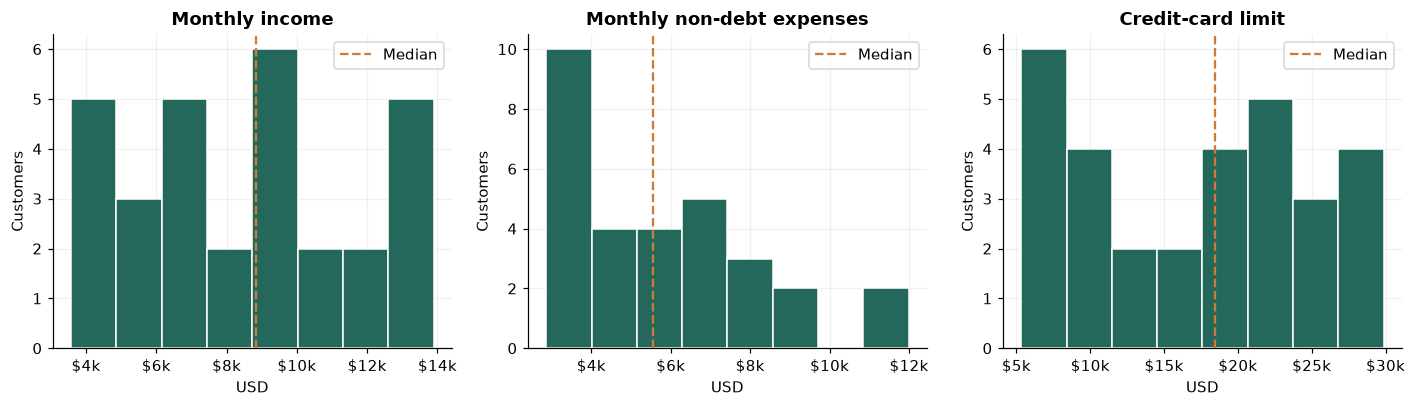

In [7]:
n = len(customer)
overview = pd.DataFrame({
    'measure': ['Customers', 'Listed account rows', 'Observed account types', 'Median monthly income (USD)',
                'Median monthly surplus (USD)', 'Customers with negative monthly surplus',
                'Median reserve runway (months)', 'Listed assets (USD)', 'Listed debts (USD)'],
    'value': [n, len(accounts), accounts.account_type.nunique(), customer.monthly_income.median(),
              customer.monthly_cash_surplus.median(), int(customer.monthly_cash_surplus.lt(0).sum()),
              customer.emergency_fund_months.median(), customer.total_assets.sum(), customer.total_debts.sum()]})
display(overview)
display(customer[['monthly_income', 'monthly_non_debt_expenses', 'credit_limit', 'account_count']]
        .describe(percentiles=[.1, .25, .5, .75, .9]).T)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, column, title in zip(axes, ['monthly_income', 'monthly_non_debt_expenses', 'credit_limit'],
                             ['Monthly income', 'Monthly non-debt expenses', 'Credit-card limit']):
    ax.hist(customer[column], bins=8, color=TEAL, edgecolor='white')
    ax.axvline(customer[column].median(), color=ORANGE, linestyle='--', label='Median')
    ax.set(title=title, xlabel='USD', ylabel='Customers')
    ax.xaxis.set_major_formatter(money_axis)
    ax.legend()
show_plot(fig, '01_profile_distributions')

## 5. Account ownership and portfolio composition

Ownership rate uses all households as its denominator. Mean and median balances **among holders** use only customers with that account type. Asset shares and debt shares have separate denominators. The sum of asset and liability balances is not net wealth or a banking portfolio valuation.

,account_rows,holders,total_balance,median_holder_balance,mean_holder_balance,total_monthly_payments,min_apr_pct,max_apr_pct,ownership_pct,category,share_within_asset_or_debt_pct
account_type,,,,,,,,,,,
checking,30,30,"153,313.73","5,383.46","5,110.46",0.00,0.00,0.00,100.00,Asset,7.55
savings,30,30,"426,247.55","12,062.85","14,208.25",0.00,0.00,0.00,100.00,Asset,20.98
cd,19,19,"139,301.17","7,227.13","7,331.64",0.00,0.00,0.00,63.33,Asset,6.86
ira,30,30,"1,312,646.35","49,300.58","43,754.88",0.00,0.00,0.00,100.00,Asset,64.61
credit_card,30,30,"165,274.85","6,466.99","5,509.16","4,958.25",22.50,22.50,100.00,Debt,3.63
auto_loan,15,15,"206,367.33","12,972.81","13,757.82","4,299.32",7.50,7.50,50.00,Debt,4.53
personal_loan,21,21,"141,204.97","6,129.05","6,724.05","3,922.33",11.00,11.00,70.00,Debt,3.10
mortgage,21,21,"4,045,657.34","232,803.29","192,650.35","26,296.76",6.50,6.50,70.00,Debt,88.75


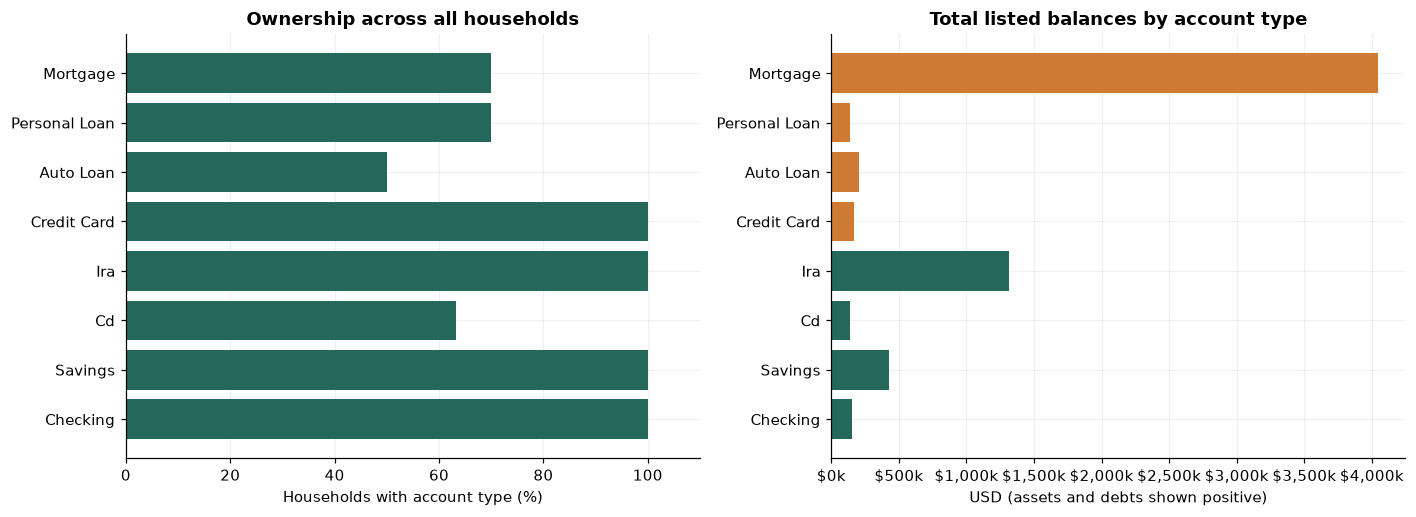

In [8]:
account_summary = accounts.groupby('account_type').agg(
    account_rows=('balance', 'size'), holders=('customer_id', 'nunique'), total_balance=('balance', 'sum'),
    median_holder_balance=('balance', 'median'), mean_holder_balance=('balance', 'mean'),
    total_monthly_payments=('monthly_payment', 'sum'), min_apr_pct=('apr_pct', 'min'), max_apr_pct=('apr_pct', 'max'))
account_summary = account_summary.reindex(TYPE_ORDER)
additive_columns = ['account_rows', 'holders', 'total_balance', 'total_monthly_payments']
account_summary[additive_columns] = account_summary[additive_columns].fillna(0)
account_summary['ownership_pct'] = 100 * account_summary.holders / n
account_summary['category'] = ['Asset' if t in ASSETS else 'Debt' for t in TYPE_ORDER]
denominators = account_summary.groupby('category').total_balance.transform('sum')
account_summary['share_within_asset_or_debt_pct'] = 100 * account_summary.total_balance / denominators.where(denominators > 0)
display(account_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
labels = [t.replace('_', ' ').title() for t in TYPE_ORDER]
axes[0].barh(labels, account_summary.ownership_pct, color=TEAL)
axes[0].set(title='Ownership across all households', xlabel='Households with account type (%)', xlim=(0, 110))
axes[1].barh(labels, account_summary.total_balance, color=[TEAL if t in ASSETS else ORANGE for t in TYPE_ORDER])
axes[1].xaxis.set_major_formatter(money_axis)
axes[1].set(title='Total listed balances by account type', xlabel='USD (assets and debts shown positive)')
show_plot(fig, '02_account_ownership_and_balances')

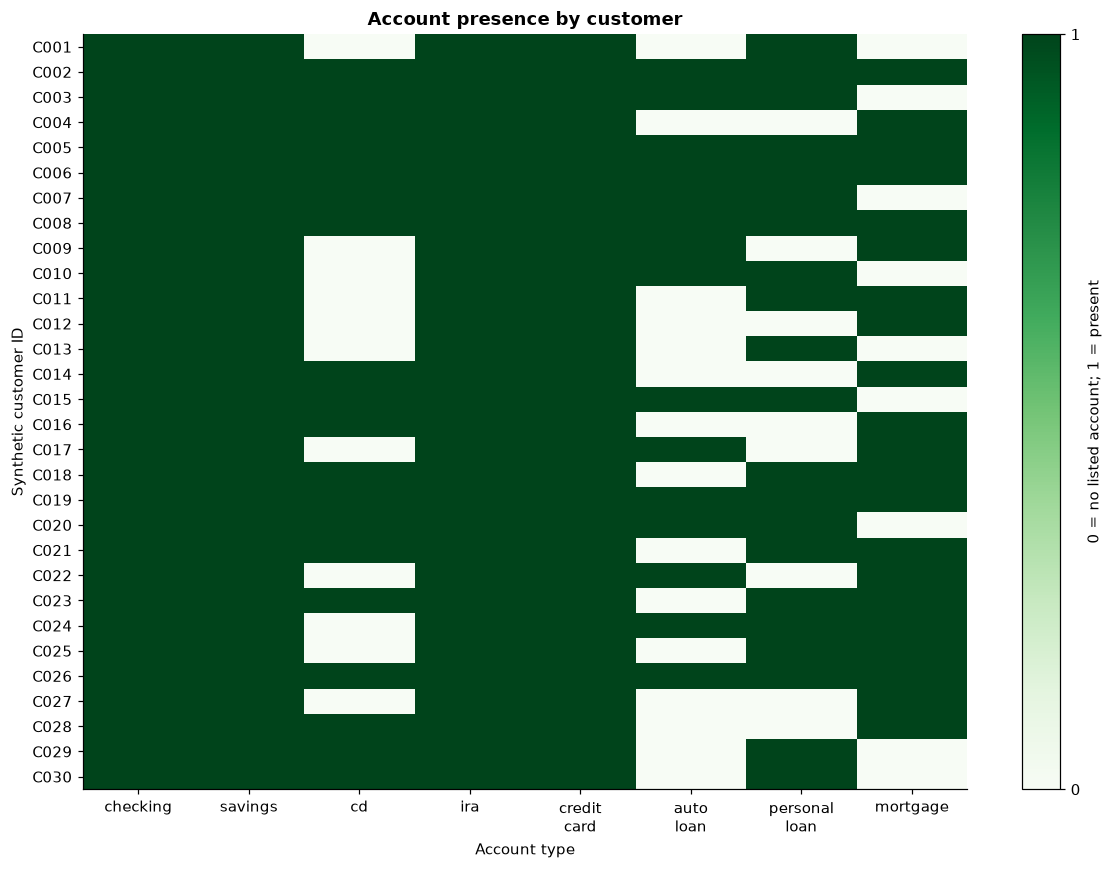

account_type,checking,savings,cd,ira,credit card,auto loan,personal loan,mortgage
Customers holding both types,,,,,,,,
checking,30,30,19,30,30,15,21,21
savings,30,30,19,30,30,15,21,21
cd,19,19,19,19,19,10,15,13
ira,30,30,19,30,30,15,21,21
credit_card,30,30,19,30,30,15,21,21
auto_loan,15,15,10,15,15,15,12,10
personal_loan,21,21,15,21,21,12,21,12
mortgage,21,21,13,21,21,10,12,21


In [9]:
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(ownership.to_numpy(), cmap='Greens', vmin=0, vmax=1, aspect='auto', interpolation='nearest')
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace('_', '\n') for t in TYPE_ORDER])
ax.set_yticks(range(n), ownership.index)
ax.set(title='Account presence by customer', xlabel='Account type', ylabel='Synthetic customer ID')
ax.grid(False)
fig.colorbar(image, ax=ax, ticks=[0, 1], label='0 = no listed account; 1 = present')
show_plot(fig, '03_account_presence')
display((ownership.T @ ownership).rename_axis('Customers holding both types').rename(columns=lambda x: x.replace('_', ' ')))

### Balance distributions, payment burden, and synthetic APR structure

The log axis below shows **positive listed balances**, excluding absent account types. Compare holder counts alongside medians. The generator sets credit-card payment to `max(30, 3% of balance)`, auto payment to `balance/48`, personal-loan payment to `balance/36`, and mortgage payment to `0.0065 × balance`. These are simplified inputs, not a complete amortization model.

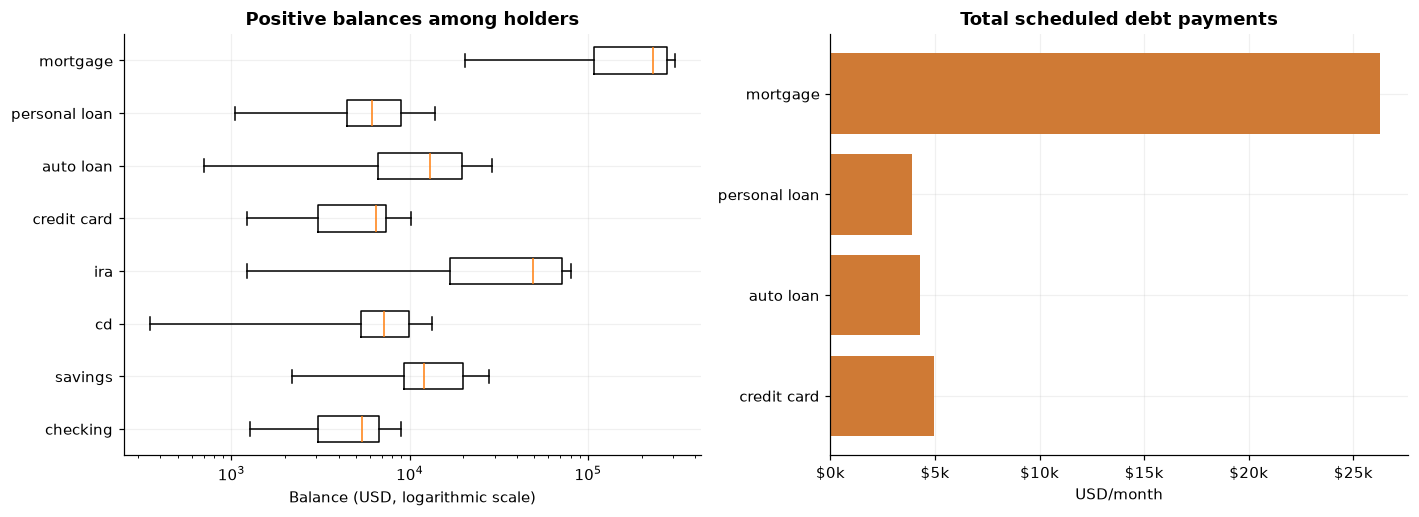

,total_balance,distinct_aprs,balance_weighted_apr_pct
account_type,,,
auto_loan,"206,367.33",1,7.50
credit_card,"165,274.85",1,22.50
mortgage,"4,045,657.34",1,6.50
personal_loan,"141,204.97",1,11.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
observed_types = [t for t in TYPE_ORDER if accounts.account_type.eq(t).any()]
axes[0].boxplot([accounts.loc[accounts.account_type.eq(t), 'balance'] for t in observed_types],
                orientation='horizontal', tick_labels=[t.replace('_', ' ') for t in observed_types])
axes[0].set_xscale('log')
axes[0].set(title='Positive balances among holders', xlabel='Balance (USD, logarithmic scale)')
payment_by_type = accounts.loc[accounts.account_type.isin(DEBTS)].groupby('account_type').monthly_payment.sum().reindex(DEBTS, fill_value=0)
axes[1].barh([t.replace('_', ' ') for t in DEBTS], payment_by_type, color=ORANGE)
axes[1].xaxis.set_major_formatter(money_axis)
axes[1].set(title='Total scheduled debt payments', xlabel='USD/month')
show_plot(fig, '04_holder_balances_and_payments')

debt_rows = accounts.loc[accounts.account_type.isin(DEBTS)].copy()
debt_rows['balance_times_apr'] = debt_rows.balance * debt_rows.apr_pct
apr_summary = debt_rows.groupby('account_type').agg(total_balance=('balance', 'sum'),
    balance_times_apr=('balance_times_apr', 'sum'), distinct_aprs=('apr_pct', 'nunique'))
apr_summary['balance_weighted_apr_pct'] = apr_summary.balance_times_apr / apr_summary.total_balance
display(apr_summary[['total_balance', 'distinct_aprs', 'balance_weighted_apr_pct']])

## 6. Cash flow, liquidity, and partial balance sheets

Cash surplus equals modeled income minus non-debt expenses and scheduled debt payments. The tool's `savings_rate_pct` is a **surplus-to-income proxy**, not an observed savings rate. Negative modeled cash flow is retained. Partial net worth excludes home values even when mortgage debt is listed, so comparisons involving mortgage holders are structurally incomplete.

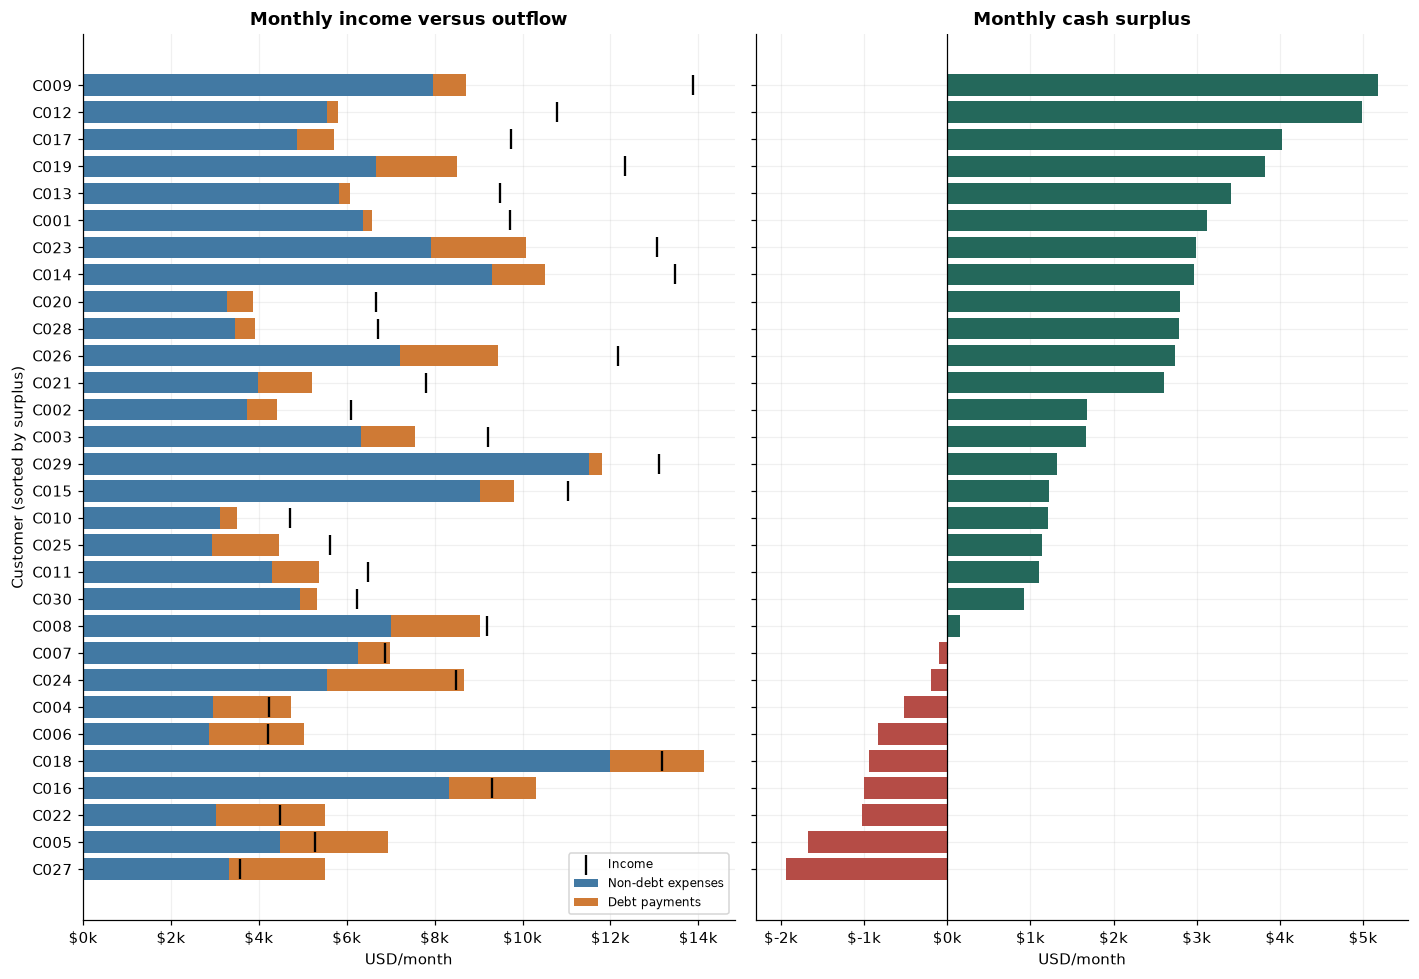

In [11]:
flow = customer.sort_values('monthly_cash_surplus').set_index('customer_id')
fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
y = np.arange(n)
axes[0].barh(y, flow.monthly_non_debt_expenses, color=BLUE, label='Non-debt expenses')
axes[0].barh(y, flow.monthly_debt_payments, left=flow.monthly_non_debt_expenses, color=ORANGE, label='Debt payments')
axes[0].scatter(flow.monthly_income, y, marker='|', s=180, color='black', label='Income')
axes[0].set_yticks(y, flow.index)
axes[0].set(title='Monthly income versus outflow', xlabel='USD/month', ylabel='Customer (sorted by surplus)')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].barh(y, flow.monthly_cash_surplus, color=np.where(flow.monthly_cash_surplus < 0, RED, TEAL))
axes[1].axvline(0, color='black', linewidth=.8)
axes[1].set(title='Monthly cash surplus', xlabel='USD/month')
for ax in axes:
    ax.xaxis.set_major_formatter(money_axis)
show_plot(fig, '05_customer_cash_flow')

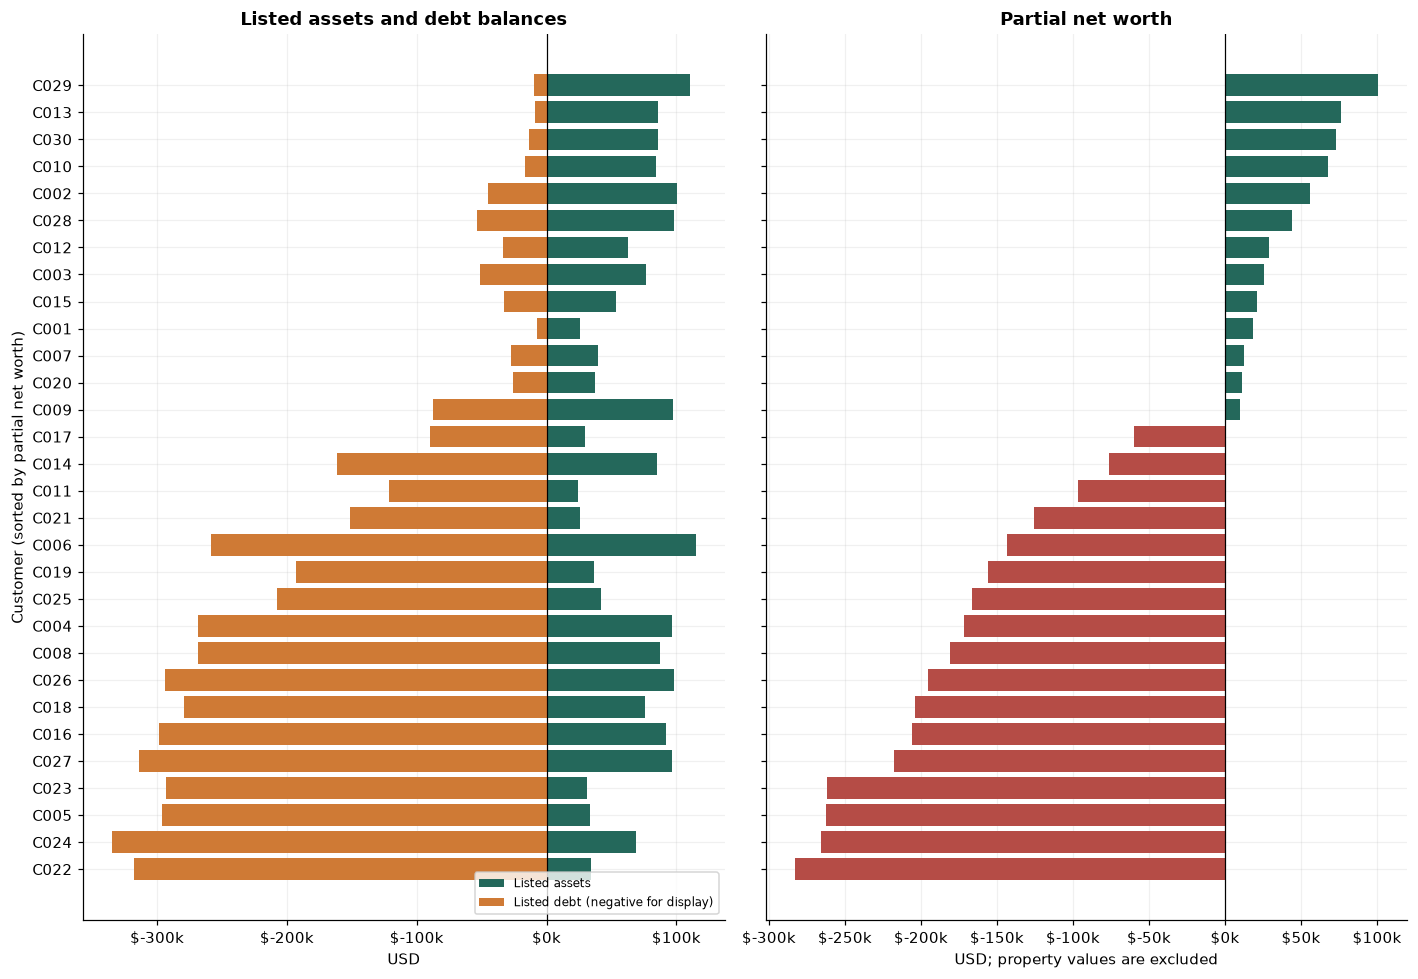

,count,mean,std,min,10%,50%,90%,max
total_assets,30.00,"67,716.96","29,895.25","24,574.37","29,362.13","76,123.91","98,616.24","114,800.27"
total_debts,30.00,"151,950.15","121,465.55","7,621.74","12,799.87","136,279.54","299,889.56","334,551.41"
liquid_assets,30.00,"19,318.71","6,893.03","8,017.57","11,178.55","19,351.56","29,109.87","31,061.56"
net_worth_partial,30.00,"-84,233.19","124,295.38","-283,008.78","-262,126.77","-86,509.25","68,458.57","100,638.26"
listed_liquid_share_pct,30.00,35.20,21.42,11.37,13.43,29.84,67.15,86.80


In [12]:
partial = customer.sort_values('net_worth_partial').set_index('customer_id')
fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
y = np.arange(n)
axes[0].barh(y, partial.total_assets, color=TEAL, label='Listed assets')
axes[0].barh(y, -partial.total_debts, color=ORANGE, label='Listed debt (negative for display)')
axes[0].set_yticks(y, partial.index)
axes[0].set(title='Listed assets and debt balances', xlabel='USD', ylabel='Customer (sorted by partial net worth)')
axes[0].legend(fontsize=8, loc='lower right')
axes[1].barh(y, partial.net_worth_partial, color=np.where(partial.net_worth_partial < 0, RED, TEAL))
axes[1].set(title='Partial net worth', xlabel='USD; property values are excluded')
for ax in axes:
    ax.axvline(0, color='black', linewidth=.8)
    ax.xaxis.set_major_formatter(money_axis)
show_plot(fig, '06_partial_balance_sheets')
display(customer[['total_assets', 'total_debts', 'liquid_assets', 'net_worth_partial',
                  'listed_liquid_share_pct']].describe(percentiles=[.1,.5,.9]).T)

## 7. Financial indicator distributions and illustrative flags

Reserve runway divides checking plus savings by all modeled required monthly outflows. Debt-payment-to-income here is not a regulated underwriting DTI calculation because the source does not identify gross income or all required obligations. Missing ratios with zero denominators stay undefined, not zero.

,count,mean,std,min,10%,25%,50%,75%,90%,max
monthly_cash_surplus,30.00,"1,454.25","1,967.91","-1,938.50","-1,008.84",-173.69,"1,272.89","2,924.76","3,836.18","5,184.32"
emergency_fund_months,30.00,2.96,1.24,1.05,1.49,2.05,2.77,3.75,4.53,5.89
debt_payment_to_income_pct,30.00,18.92,16.87,2.18,2.64,7.36,14.15,21.93,47.06,61.25
credit_card_utilization_pct,30.00,40.59,36.41,7.15,13.36,18.13,30.70,46.58,79.32,187.00
savings_rate_pct,30.00,13.07,24.64,-54.18,-20.24,-2.11,19.22,31.87,41.31,46.16
net_worth_partial,30.00,"-84,233.19","124,295.38","-283,008.78","-262,126.77","-191,859.46","-86,509.25","24,682.65","68,458.57","100,638.26"
liquid_assets_to_debt_pct,30.00,48.01,71.08,3.81,5.81,7.41,12.22,48.06,135.97,252.51
monthly_debt_payments,30.00,"1,315.89",836.31,226.31,282.86,626.39,"1,219.43","2,109.08","2,251.20","3,119.04"


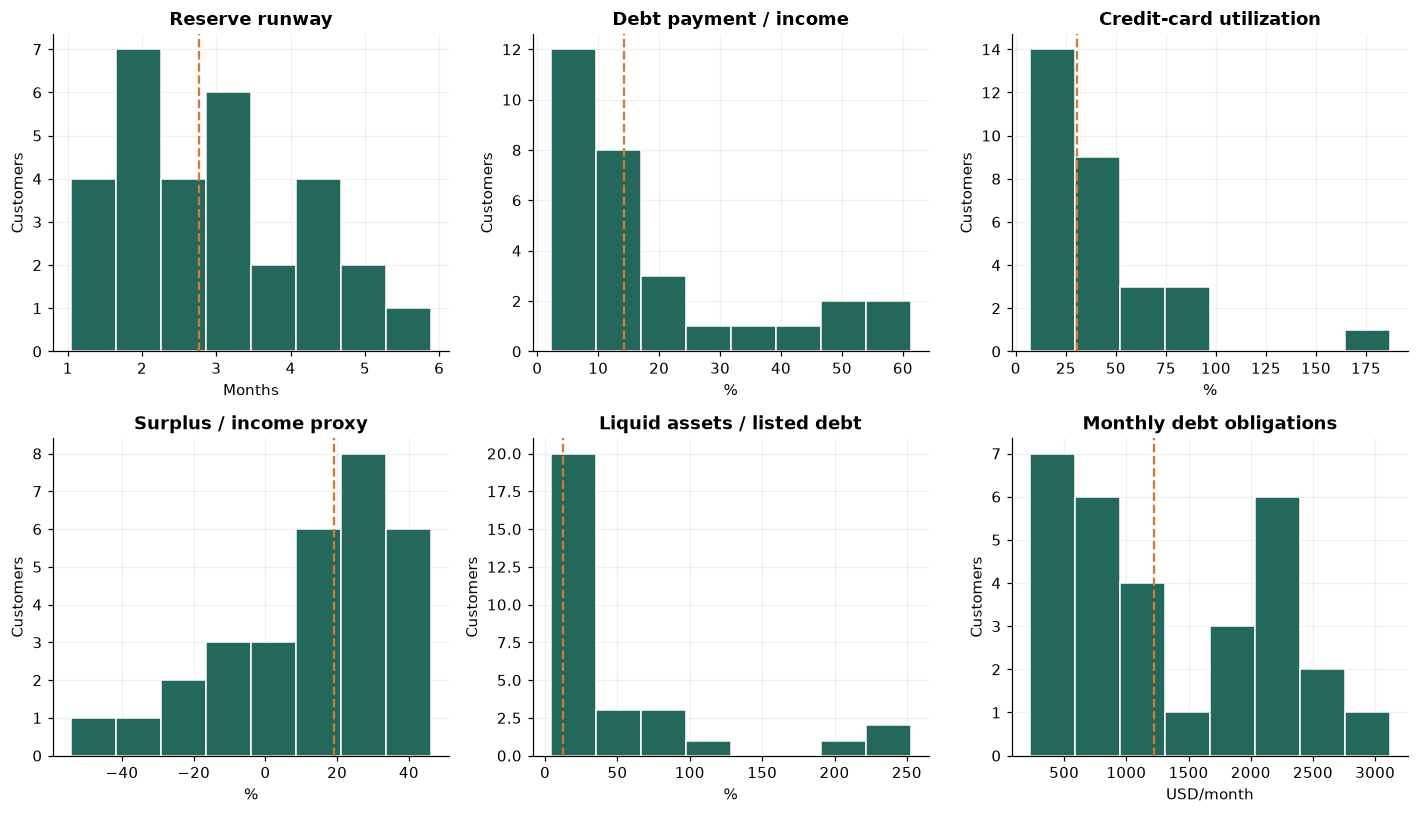

,customers,denominator,pct
negative_cash_surplus,9,30,30.00
reserves_below_3_months,17,30,56.67
utilization_above_30_pct,16,30,53.33
utilization_above_100_pct,1,30,3.33
negative_partial_net_worth,17,30,56.67


Flags are descriptive workshop examples. No composite score or eligibility decision is calculated.


In [13]:
display(customer[metric_columns].describe(percentiles=[.1,.25,.5,.75,.9]).T)
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, column, title, unit in zip(axes.flat,
    ['emergency_fund_months', 'debt_payment_to_income_pct', 'credit_card_utilization_pct',
     'savings_rate_pct', 'liquid_assets_to_debt_pct', 'monthly_debt_payments'],
    ['Reserve runway', 'Debt payment / income', 'Credit-card utilization',
     'Surplus / income proxy', 'Liquid assets / listed debt', 'Monthly debt obligations'],
    ['Months', '%', '%', '%', '%', 'USD/month']):
    values = customer[column].dropna()
    ax.hist(values, bins=8, color=TEAL, edgecolor='white')
    ax.set(title=title, xlabel=unit, ylabel='Customers')
    if not values.empty:
        ax.axvline(values.median(), linestyle='--', color=ORANGE)
show_plot(fig, '07_indicator_distributions')

flag_table = pd.DataFrame({
    'negative_cash_surplus': customer.monthly_cash_surplus.lt(0),
    f'reserves_below_{RESERVE_REFERENCE_MONTHS:g}_months': customer.emergency_fund_months.lt(RESERVE_REFERENCE_MONTHS),
    f'utilization_above_{UTILIZATION_REFERENCE_PCT:g}_pct': customer.credit_card_utilization_pct.gt(UTILIZATION_REFERENCE_PCT),
    'utilization_above_100_pct': customer.credit_card_utilization_pct.gt(100),
    'negative_partial_net_worth': customer.net_worth_partial.lt(0),
}, index=customer.index)
flag_summary = pd.DataFrame({'customers': flag_table.sum(), 'denominator': n})
flag_summary['pct'] = 100 * flag_summary.customers / flag_summary.denominator
display(flag_summary)
print('Flags are descriptive workshop examples. No composite score or eligibility decision is calculated.')

In [14]:
# Distinguish average household ratios from ratios of aggregated amounts.
portfolio_ratios = pd.DataFrame([
    ['Debt payment / income (%)', customer.debt_payment_to_income_pct.mean(),
      customer.debt_payment_to_income_pct.median(), 100 * customer.monthly_debt_payments.sum() / customer.monthly_income.sum()],
    ['Credit-card utilization (%)', customer.credit_card_utilization_pct.mean(),
      customer.credit_card_utilization_pct.median(), 100 * customer.balance_credit_card.sum() / customer.credit_limit.sum()],
    ['Surplus / income proxy (%)', customer.savings_rate_pct.mean(), customer.savings_rate_pct.median(),
      100 * customer.monthly_cash_surplus.sum() / customer.monthly_income.sum()],
    ['Reserve runway (months)', customer.emergency_fund_months.mean(), customer.emergency_fund_months.median(),
      customer.liquid_assets.sum() / customer.monthly_outflow.sum()],
], columns=['measure', 'household_mean', 'household_median', 'ratio_of_portfolio_totals'])
display(portfolio_ratios)
display(pd.DataFrame([{'reserve_reference_months': threshold,
    'customers_below': int(customer.emergency_fund_months.lt(threshold).sum()), 'total_customers': n}
    for threshold in [1, 2, 3, 6]]))

,measure,household_mean,household_median,ratio_of_portfolio_totals
0,Debt payment / income (%),18.92,14.15,15.35
1,Credit-card utilization (%),40.59,30.70,32.22
2,Surplus / income proxy (%),13.07,19.22,16.96
3,Reserve runway (months),2.96,2.77,2.71


,reserve_reference_months,customers_below,total_customers
0,1,0,30
1,2,7,30
2,3,17,30
3,6,30,30


## 8. Relationships and descriptive segments

Pearson correlation summarizes linear association; Spearman correlation summarizes rank association. With a tiny, designed sample these are descriptive, without hypothesis tests or causal claims. Some relationships are mathematical: surplus is income minus outflow; reserve runway includes outflow in its denominator; the savings proxy is surplus divided by income. Do not treat these as independent predictive discoveries.

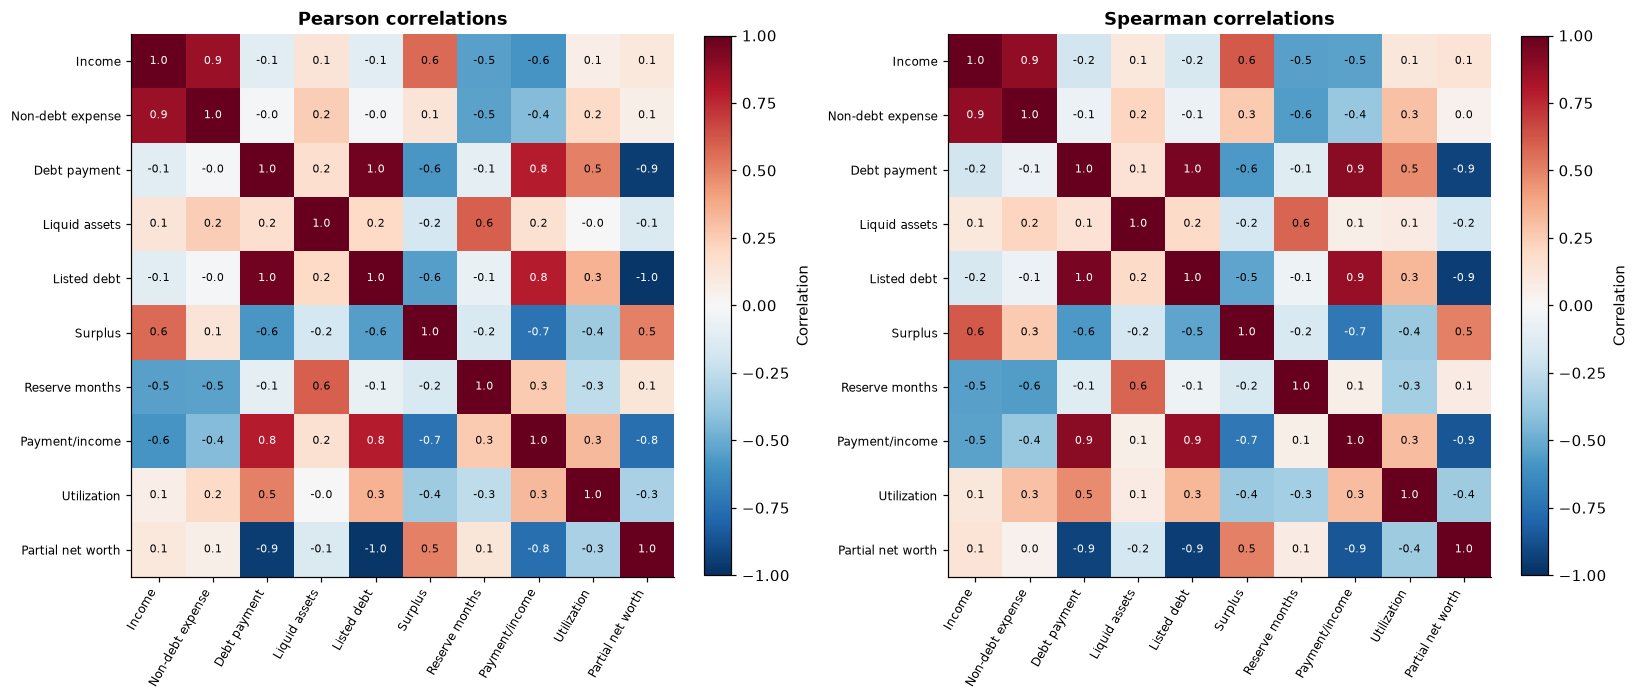

In [15]:
corr_columns = ['monthly_income', 'monthly_non_debt_expenses', 'monthly_debt_payments',
                'liquid_assets', 'total_debts', 'monthly_cash_surplus', 'emergency_fund_months',
                'debt_payment_to_income_pct', 'credit_card_utilization_pct', 'net_worth_partial']
short_labels = ['Income', 'Non-debt expense', 'Debt payment', 'Liquid assets', 'Listed debt',
                'Surplus', 'Reserve months', 'Payment/income', 'Utilization', 'Partial net worth']
pearson = customer[corr_columns].corr(method='pearson')
spearman = customer[corr_columns].corr(method='spearman')
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, corr, title in [(axes[0], pearson, 'Pearson correlations'), (axes[1], spearman, 'Spearman correlations')]:
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(corr_columns)), short_labels, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(corr_columns)), short_labels, fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    for row in range(len(corr_columns)):
        for col in range(len(corr_columns)):
            value = corr.iloc[row, col]
            ax.text(col, row, f'{value:.1f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(value) > .65 else 'black')
    fig.colorbar(image, ax=ax, fraction=.045, label='Correlation')
show_plot(fig, '08_correlations')

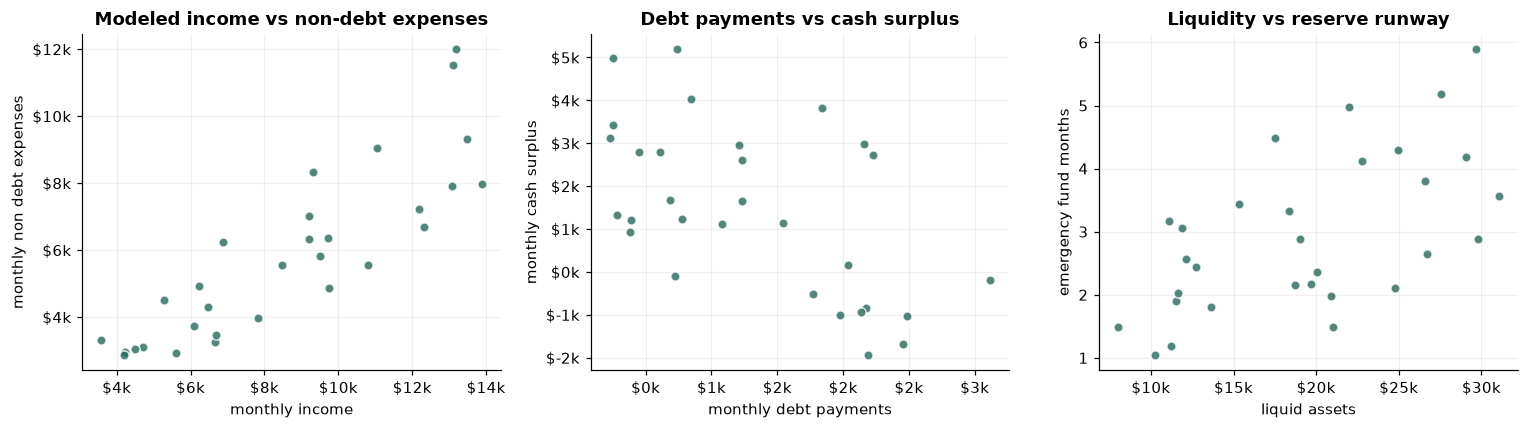

,customers,median_income,median_surplus,median_reserve_months,negative_surplus_customers,negative_surplus_pct
income_band,,,,,,
"(3578.1789999999996, 6608.427]",10,"4,992.01",203.35,3.78,5,50.00
"(6608.427, 9720.847]",10,"8,836.24","2,137.22",2.67,3,30.00
"(9720.847, 13888.01]",10,"12,700.92","2,977.88",2.07,1,10.00


,customers,median_listed_debt,median_partial_net_worth,median_surplus
mortgage_listed,,,,
False,9,"16,480.07","25,785.77","1,316.54"
True,21,"258,352.78","-166,162.87","1,143.30"


Income-band endpoints are USD/month and derived from this sample; mortgage groups lack home values.


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pairs = [('monthly_income', 'monthly_non_debt_expenses', 'Modeled income vs non-debt expenses'),
         ('monthly_debt_payments', 'monthly_cash_surplus', 'Debt payments vs cash surplus'),
         ('liquid_assets', 'emergency_fund_months', 'Liquidity vs reserve runway')]
for ax, (x, y, title) in zip(axes, pairs):
    ax.scatter(customer[x], customer[y], color=TEAL, alpha=.8, edgecolor='white')
    ax.set(title=title, xlabel=x.replace('_', ' '), ylabel=y.replace('_', ' '))
    ax.xaxis.set_major_formatter(money_axis)
    if y != 'emergency_fund_months':
        ax.yaxis.set_major_formatter(money_axis)
show_plot(fig, '09_relationships')

customer['income_band'] = pd.qcut(customer.monthly_income, q=3, duplicates='drop')
customer['mortgage_listed'] = customer.balance_mortgage.gt(0)
segment_summary = customer.groupby('income_band', observed=True).agg(
    customers=('customer_id', 'size'), median_income=('monthly_income', 'median'),
    median_surplus=('monthly_cash_surplus', 'median'), median_reserve_months=('emergency_fund_months', 'median'),
    negative_surplus_customers=('monthly_cash_surplus', lambda s: s.lt(0).sum()))
segment_summary['negative_surplus_pct'] = 100 * segment_summary.negative_surplus_customers / segment_summary.customers
display(segment_summary)
display(customer.groupby('mortgage_listed', observed=True).agg(customers=('customer_id', 'size'),
    median_listed_debt=('total_debts', 'median'), median_partial_net_worth=('net_worth_partial', 'median'),
    median_surplus=('monthly_cash_surplus', 'median')))
print('Income-band endpoints are USD/month and derived from this sample; mortgage groups lack home values.')

## 9. Unusual observations and concentration

Tukey's 1.5×IQR rule highlights observations to inspect. A flag does not prove an error, and no record is removed. A concentrated generated debt balance can dominate portfolio totals despite a modest household median. Group differences and outliers may be consequences of generator choices.

,metric,customer_id,value,lower_fence,upper_fence
0,credit_card_utilization_pct,C003,93.93,-24.54,89.25
1,credit_card_utilization_pct,C018,94.17,-24.54,89.25
2,credit_card_utilization_pct,C024,187.00,-24.54,89.25


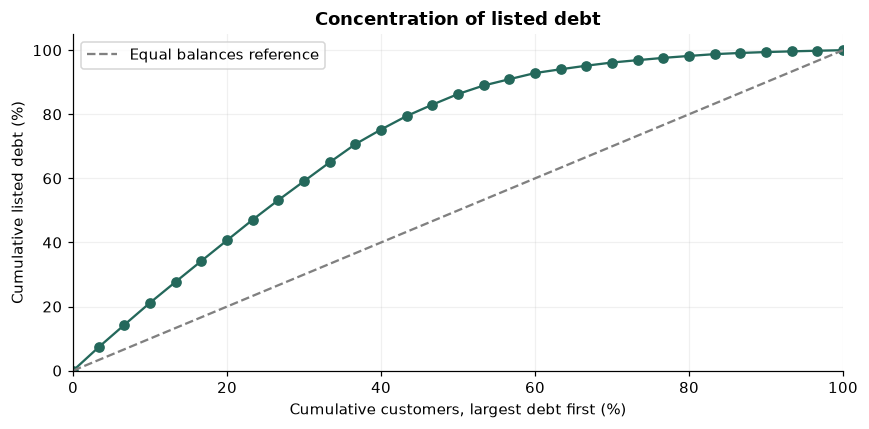

,customer_id,total_debts,balance_mortgage,cumulative_debt_pct
23,C024,"334,551.41","281,770.84",7.34
21,C022,"317,443.97","294,563.02",14.30
26,C027,"314,191.95","307,829.42",21.20
15,C016,"298,300.41","296,604.29",27.74
4,C005,"295,989.43","266,087.27",34.23


In [17]:
outlier_rows = []
outlier_columns = ['monthly_income', 'monthly_cash_surplus', 'total_debts', 'liquid_assets',
                   'credit_card_utilization_pct', 'net_worth_partial']
for metric in outlier_columns:
    q1, q3 = customer[metric].quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = customer.loc[customer[metric].lt(low) | customer[metric].gt(high)]
    for _, row in flagged.iterrows():
        outlier_rows.append({'metric': metric, 'customer_id': row.customer_id, 'value': row[metric],
                             'lower_fence': low, 'upper_fence': high})
outliers = pd.DataFrame(outlier_rows, columns=['metric', 'customer_id', 'value', 'lower_fence', 'upper_fence'])
display(outliers if not outliers.empty else pd.DataFrame({'result': ['No IQR outliers in selected measures']}))

debt_rank = customer.sort_values('total_debts', ascending=False).copy()
total_debt = debt_rank.total_debts.sum()
debt_rank['cumulative_customer_pct'] = 100 * np.arange(1, n + 1) / n
debt_rank['cumulative_debt_pct'] = 100 * debt_rank.total_debts.cumsum() / total_debt if total_debt > 0 else np.nan
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.r_[0, debt_rank.cumulative_customer_pct], np.r_[0, debt_rank.cumulative_debt_pct], marker='o', color=TEAL)
ax.plot([0, 100], [0, 100], linestyle='--', color='gray', label='Equal balances reference')
ax.set(title='Concentration of listed debt', xlabel='Cumulative customers, largest debt first (%)',
       ylabel='Cumulative listed debt (%)', xlim=(0,100), ylim=(0,105))
ax.legend()
show_plot(fig, '10_debt_concentration')
display(debt_rank[['customer_id', 'total_debts', 'balance_mortgage', 'cumulative_debt_pct']].head(5))

## 10. Scenario analysis: vehicle purchase and household stress

Scenarios are deterministic counterfactual calculations, not forecasts. The vehicle simulator adds a new payment on top of existing obligations and subtracts the down payment from checking plus savings. It omits taxes, insurance, maintenance, fees, asset depreciation, and resale value. Existing auto loans are not replaced. If down payment exceeds available liquidity, the simulator can return negative reserves; we flag this as an unmet cash requirement rather than an affordable transaction.

,purchase_price,down_payment,apr_pct,term_months
0,30000,5000,8.00,60


,customer_id,new_monthly_payment,projected_monthly_surplus,remaining_liquid_assets,projected_emergency_fund_months,monthly_cash_surplus,liquid_assets,emergency_fund_months,down_payment_exceeds_liquidity,negative_projected_surplus,surplus_change
26,C027,506.91,"-2,445.41","13,333.34",2.21,"-1,938.50","18,333.34",3.32,False,True,-506.91
4,C005,506.91,"-2,179.98","24,048.17",3.23,"-1,673.07","29,048.17",4.18,False,True,-506.91
21,C022,506.91,"-1,531.28","17,745.64",2.95,"-1,024.37","22,745.64",4.13,False,True,-506.91
15,C016,506.91,"-1,514.02","24,789.32",2.29,"-1,007.11","29,789.32",2.89,False,True,-506.91
17,C018,506.91,"-1,452.26","16,023.91",1.10,-945.35,"21,023.91",1.49,False,True,-506.91
5,C006,506.91,"-1,344.85","24,665.16",4.45,-837.94,"29,665.16",5.89,False,True,-506.91
3,C004,506.91,"-1,024.67","7,131.69",1.36,-517.76,"12,131.69",2.56,False,True,-506.91
23,C024,506.91,-707.21,"13,700.09",1.49,-200.30,"18,700.09",2.16,False,True,-506.91
6,C007,506.91,-600.76,"21,579.86",2.88,-93.85,"26,579.86",3.81,False,True,-506.91
7,C008,506.91,-348.78,"14,682.52",1.54,158.13,"19,682.52",2.18,False,True,-506.91


,scenario_check,customers,denominator
0,Down payment exceeds liquid assets,0,30
1,Negative projected surplus,10,30
2,Projected reserves below 3 months,25,30


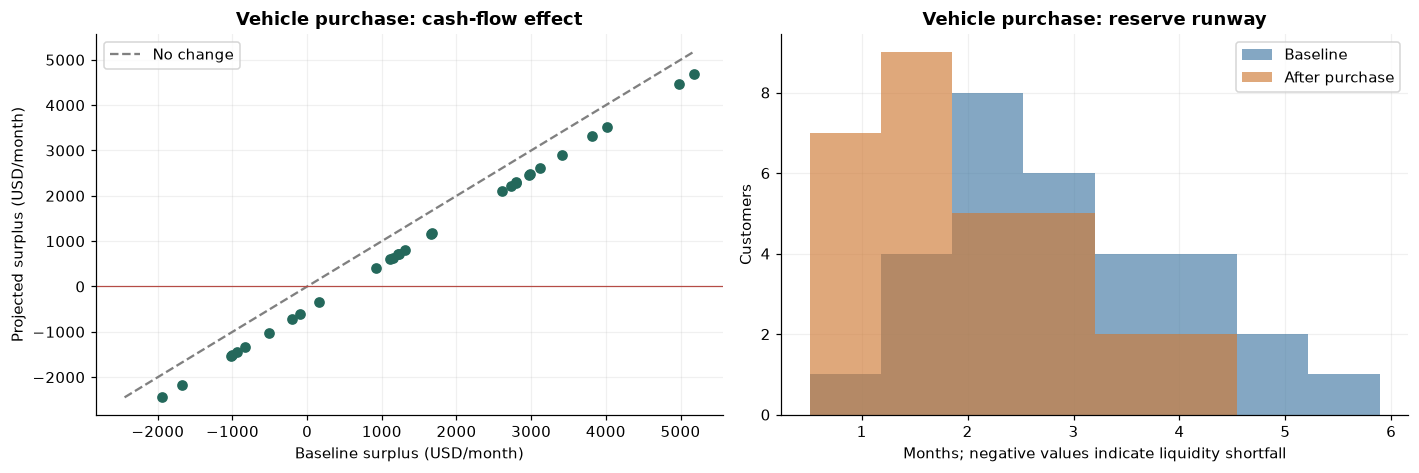

In [18]:
vehicle_rows = []
for cid in customer.customer_id:
    result = tools.simulate_purchase(cid, **VEHICLE)
    vehicle_rows.append({key: value for key, value in result.items() if key not in ['assumptions', 'caveat']})
vehicle = pd.DataFrame(vehicle_rows).merge(customer[['customer_id', 'monthly_cash_surplus', 'liquid_assets',
    'emergency_fund_months']], on='customer_id', validate='one_to_one')
vehicle['down_payment_exceeds_liquidity'] = vehicle.remaining_liquid_assets.lt(0)
vehicle['negative_projected_surplus'] = vehicle.projected_monthly_surplus.lt(0)
vehicle['surplus_change'] = vehicle.projected_monthly_surplus - vehicle.monthly_cash_surplus
assert np.allclose(vehicle.surplus_change, -vehicle.new_monthly_payment, atol=.02)
assert np.allclose(vehicle.remaining_liquid_assets, vehicle.liquid_assets - VEHICLE['down_payment'], atol=.011)
display(pd.DataFrame([VEHICLE]))
display(vehicle.sort_values('projected_monthly_surplus').head(10))
display(pd.DataFrame({'scenario_check': ['Down payment exceeds liquid assets', 'Negative projected surplus',
    f'Projected reserves below {RESERVE_REFERENCE_MONTHS:g} months'],
    'customers': [vehicle.down_payment_exceeds_liquidity.sum(), vehicle.negative_projected_surplus.sum(),
                  vehicle.projected_emergency_fund_months.lt(RESERVE_REFERENCE_MONTHS).sum()], 'denominator': n}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(vehicle.monthly_cash_surplus, vehicle.projected_monthly_surplus, color=TEAL)
lims = [min(vehicle.monthly_cash_surplus.min(), vehicle.projected_monthly_surplus.min()),
        max(vehicle.monthly_cash_surplus.max(), vehicle.projected_monthly_surplus.max())]
axes[0].plot(lims, lims, color='gray', linestyle='--', label='No change')
axes[0].axhline(0, color=RED, linewidth=.8)
axes[0].set(title='Vehicle purchase: cash-flow effect', xlabel='Baseline surplus (USD/month)', ylabel='Projected surplus (USD/month)')
axes[0].legend()
reserve_bins = np.histogram_bin_edges(pd.concat([vehicle.emergency_fund_months,
                                               vehicle.projected_emergency_fund_months]).dropna(), bins=8)
axes[1].hist(vehicle.emergency_fund_months, bins=reserve_bins, alpha=.65, color=BLUE, label='Baseline')
axes[1].hist(vehicle.projected_emergency_fund_months, bins=reserve_bins, alpha=.65, color=ORANGE, label='After purchase')
axes[1].set(title='Vehicle purchase: reserve runway', xlabel='Months; negative values indicate liquidity shortfall', ylabel='Customers')
axes[1].legend()
show_plot(fig, '11_vehicle_effect')

### APR and term sensitivity

Use the same purchase price and down payment for every customer. The heatmaps count customers with negative projected surplus at each APR/term pair, and show the corresponding new monthly payment. These counts do not assess credit eligibility or all ownership costs.

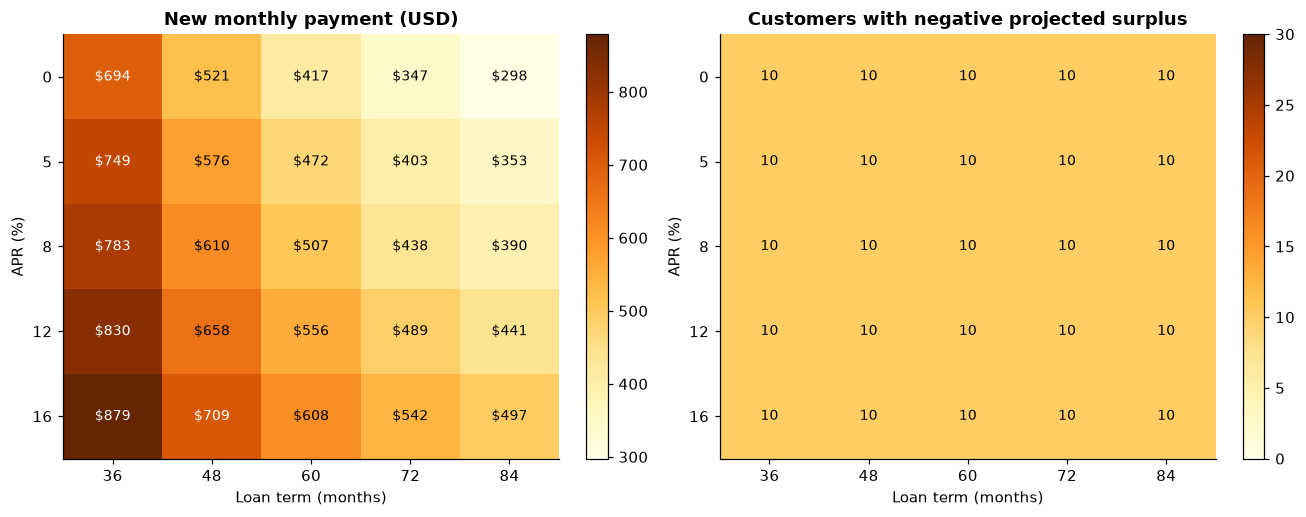

The negative-surplus count is unchanged across this APR/term grid; payments still vary. This is a property of these inputs and this sample, not general insensitivity to financing terms.


In [19]:
sensitivity_rows = []
for apr in [0, 5, 8, 12, 16]:
    for term in [36, 48, 60, 72, 84]:
        results = [tools.simulate_purchase(cid, VEHICLE['purchase_price'], VEHICLE['down_payment'], apr, term)
                   for cid in customer.customer_id]
        sensitivity_rows.append({'apr_pct': apr, 'term_months': term,
            'payment': results[0]['new_monthly_payment'],
            'negative_surplus_customers': sum(r['projected_monthly_surplus'] < 0 for r in results)})
sensitivity = pd.DataFrame(sensitivity_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, value, title, fmt in [(axes[0], 'payment', 'New monthly payment (USD)', '${:,.0f}'),
                             (axes[1], 'negative_surplus_customers', 'Customers with negative projected surplus', '{:.0f}')]:
    matrix = sensitivity.pivot(index='apr_pct', columns='term_months', values=value)
    limits = {'vmin': 0, 'vmax': n} if value == 'negative_surplus_customers' else {}
    image = ax.imshow(matrix, cmap='YlOrBr', aspect='auto', **limits)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(title=title, xlabel='Loan term (months)', ylabel='APR (%)')
    ax.grid(False)
    for r in range(len(matrix.index)):
        for c in range(len(matrix.columns)):
            normalized = image.norm(matrix.iloc[r,c])
            ax.text(c, r, fmt.format(matrix.iloc[r,c]), ha='center', va='center', fontsize=9,
                    color='white' if normalized > .65 else 'black')
    fig.colorbar(image, ax=ax, fraction=.045)
show_plot(fig, '12_vehicle_sensitivity')
if sensitivity.negative_surplus_customers.nunique() == 1:
    print('The negative-surplus count is unchanged across this APR/term grid; payments still vary. '
          'This is a property of these inputs and this sample, not general insensitivity to financing terms.')

### Separate income and expense stress grid

Reduce modeled income by 0–30% and increase non-debt expenses by 0–20%, holding scheduled debt payments and liquid balances constant. This is a static monthly counterfactual, not an unemployment forecast or a simulation of how households adapt. It does not include the vehicle purchase.

,income_drop_pct,expense_increase_pct,median_surplus,negative_surplus_customers,negative_surplus_pct
0,0.00,0.00,"1,272.89",9,30.00
1,0.00,10.00,876.86,10,33.33
2,0.00,20.00,479.12,13,43.33
3,10.00,0.00,661.83,10,33.33
4,10.00,10.00,200.00,13,43.33
5,10.00,20.00,-321.72,17,56.67
6,20.00,0.00,-79.12,15,50.00
7,20.00,10.00,-639.60,20,66.67
8,20.00,20.00,"-1,259.61",22,73.33
9,30.00,0.00,-939.50,21,70.00


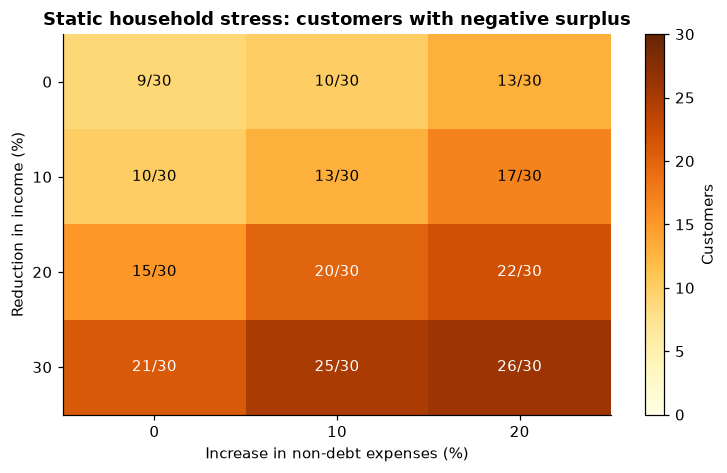

In [20]:
stress_rows = []
for income_drop in [0, .1, .2, .3]:
    for expense_increase in [0, .1, .2]:
        income = customer.monthly_income * (1 - income_drop)
        outflow = customer.monthly_non_debt_expenses * (1 + expense_increase) + customer.monthly_debt_payments
        surplus = income - outflow
        stress_rows.append({'income_drop_pct': 100 * income_drop, 'expense_increase_pct': 100 * expense_increase,
            'median_surplus': surplus.median(), 'negative_surplus_customers': int(surplus.lt(0).sum()),
            'negative_surplus_pct': 100 * surplus.lt(0).mean()})
stress = pd.DataFrame(stress_rows)
display(stress)
assert stress.loc[(stress.income_drop_pct == 0) & (stress.expense_increase_pct == 0),
                  'negative_surplus_customers'].iloc[0] == customer.monthly_cash_surplus.lt(0).sum()
matrix = stress.pivot(index='income_drop_pct', columns='expense_increase_pct', values='negative_surplus_customers')
fig, ax = plt.subplots(figsize=(7, 4.4))
image = ax.imshow(matrix, cmap='YlOrBr', vmin=0, vmax=n, aspect='auto')
ax.set_xticks(range(len(matrix.columns)), matrix.columns.astype(int))
ax.set_yticks(range(len(matrix.index)), matrix.index.astype(int))
ax.set(title='Static household stress: customers with negative surplus',
       xlabel='Increase in non-debt expenses (%)', ylabel='Reduction in income (%)')
ax.grid(False)
for r in range(len(matrix.index)):
    for c in range(len(matrix.columns)):
        ax.text(c, r, f'{matrix.iloc[r,c]:.0f}/{n}', ha='center', va='center',
                color='white' if matrix.iloc[r,c] / n > .65 else 'black')
fig.colorbar(image, ax=ax, label='Customers')
show_plot(fig, '13_income_expense_stress')

## 11. Transaction history: 24 complete months

The supplied history spans **November 2024 through October 2026** for every listed account. `transactions.csv` contains posted ledger entries and `monthly_statements.csv` contains opening balances, increases, decreases, and closing balances for each account/month. `history_manifest.json` records the seed, dates, counts, and limitations. No snapshot balances were changed when adding history.

**Balance convention:** assets and liabilities are both positive. A positive `balance_change` increases the account balance; a payment decreases a liability. `amount` is always positive. `balance_after` is the running account balance after that entry. Sort by date and transaction ID to preserve posting order.

**Economic meaning:** paychecks are income. Deposit-account expenses and card purchases are spending. Matched transfers, including checking-to-loan and checking-to-card payments, are not additional spending. Loan/card interest and fees are separate charges. Savings/CD/IRA interest is a non-cash synthetic accrual; the IRA is an interest-only teaching model without market gains, eligibility rules, or tax treatment.

**Calibration:** the generator back-solves openings and uses explicitly labeled external cash-management transfers to preserve the original ending snapshots. These transfers represent unlisted external accounts, are not earned income or consumption, and must not be used as evidence of actual saving behavior. Payroll, spending seasonality, and fees are artificial design choices. The profile's income/expense values and scheduled payments remain snapshot assumptions; historical monthly averages may differ.

In [21]:
from financial_tools import summarize_transaction_history, get_transactions, get_account_history
history_manifest = json.loads((DATA / 'history_manifest.json').read_text())
transactions = pd.read_csv(DATA / 'transactions.csv', keep_default_na=False,
    dtype={'transaction_id': 'string', 'account_id': 'string', 'customer_id': 'string', 'transfer_id': 'string'})
statements = pd.read_csv(DATA / 'monthly_statements.csv', dtype={'account_id': 'string', 'customer_id': 'string'})
transactions['posted_date'] = pd.to_datetime(transactions.posted_date, errors='raise')
transactions['month'] = transactions.posted_date.dt.strftime('%Y-%m')
display(pd.DataFrame([history_manifest]))
display(pd.DataFrame([
    ['transaction_id', 'Stable ledger identifier; resolves same-day posting order'],
    ['account_id / customer_id', 'Account and owner keys; no transaction can cross customer scope'],
    ['posted_date / month', 'Synthetic posting day and calendar reporting month'],
    ['transaction_type / category', 'Paycheck, deposit, withdrawal, purchase, accrual, fee, or payment and purpose'],
    ['amount / balance_change / balance_after', 'Positive USD amount, signed account movement, running account balance'],
    ['flow_class', 'income, expense, internal_transfer, external_transfer, or non_cash'],
    ['transfer_id', 'Exactly two matching legs for internal transfers; empty for other entries'],
], columns=['field', 'meaning']))
display(transactions.head(10))

,schema_version,seed,history_start,as_of_date,months,customers,accounts,transactions,monthly_statements,currency,balance_convention,calibration,limitations
0,2,20261108,2024-11-01,2026-10-31,24,30,196,21225,4704,USD,Assets and liabilities are positive; balance_c...,Opening balances and explicit external cash-ma...,"Synthetic monthly accrual, no daily compoundin..."


,field,meaning
0,transaction_id,Stable ledger identifier; resolves same-day po...
1,account_id / customer_id,Account and owner keys; no transaction can cro...
2,posted_date / month,Synthetic posting day and calendar reporting m...
3,transaction_type / category,"Paycheck, deposit, withdrawal, purchase, accru..."
4,amount / balance_change / balance_after,"Positive USD amount, signed account movement, ..."
5,flow_class,"income, expense, internal_transfer, external_t..."
6,transfer_id,Exactly two matching legs for internal transfe...


,transaction_id,customer_id,account_id,account_type,posted_date,transaction_type,category,description,amount,balance_change,balance_after,flow_class,transfer_id,month
0,T0000001,C001,A-C001-CHECKING,checking,2024-11-01,paycheck,payroll,Paycheck,"4,585.97","4,585.97","6,029.57",income,,2024-11
1,T0000002,C001,A-C001-CHECKING,checking,2024-11-03,payment,housing,Payment,"2,325.95","-2,325.95","3,703.62",expense,,2024-11
2,T0000003,C001,A-C001-CHECKING,checking,2024-11-05,transfer_out,savings_contribution,Synthetic linked savings deposit,34.55,-34.55,"3,669.07",internal_transfer,X-C001-savings-00-deposit,2024-11
3,T0000004,C001,A-C001-CHECKING,checking,2024-11-05,transfer_out,investment_contribution,Synthetic linked ira deposit,27.23,-27.23,"3,641.84",internal_transfer,X-C001-ira-00-deposit,2024-11
4,T0000005,C001,A-C001-CHECKING,checking,2024-11-10,payment,utilities,Payment,"1,033.75","-1,033.75","2,608.09",expense,,2024-11
5,T0000006,C001,A-C001-CHECKING,checking,2024-11-15,paycheck,payroll,Paycheck,"4,585.97","4,585.97","7,194.06",income,,2024-11
6,T0000007,C001,A-C001-CHECKING,checking,2024-11-18,withdrawal,groceries,Withdrawal,775.31,-775.31,"6,418.75",expense,,2024-11
7,T0000008,C001,A-C001-CHECKING,checking,2024-11-21,payment,debt_payment,Synthetic linked personal loan payment,16.99,-16.99,"6,401.76",internal_transfer,X-C001-personal_loan-00-payment,2024-11
8,T0000009,C001,A-C001-CHECKING,checking,2024-11-25,payment,other_spending,Payment,"1,033.77","-1,033.77","5,367.99",expense,,2024-11
9,T0000010,C001,A-C001-CHECKING,checking,2024-11-28,payment,debt_payment,Synthetic linked credit card payment,"1,578.05","-1,578.05","3,789.94",internal_transfer,X-C001-credit_card-00-payment,2024-11


### Validate ledger keys, ownership, signs, coverage, and transfers

These checks use integer cents. A paired transfer has the same owner, day, and amount on both legs. Its net economic balance change is zero after liabilities are assigned the opposite sign from assets. Two negative balance changes on a checking-to-loan payment are therefore correct: cash and the liability both decrease.

In [22]:
history_checks = []
def history_check(name, passed):
    history_checks.append({'check': name, 'passed': bool(passed)})

for column in ['amount', 'balance_change', 'balance_after']:
    transactions[column] = pd.to_numeric(transactions[column], errors='raise')
    history_check(f'{column}: finite', np.isfinite(transactions[column]).all())
    transactions[column + '_cents'] = np.rint(transactions[column] * 100).astype('int64')
history_check('Unique transaction IDs', transactions.transaction_id.is_unique)
history_check('Unique account IDs', accounts.account_id.is_unique)
history_check('Positive amounts and nonnegative running balances', transactions.amount.gt(0).all() and transactions.balance_after.ge(0).all())
history_check('Absolute movement equals amount', transactions.balance_change_cents.abs().eq(transactions.amount_cents).all())
owner = transactions.merge(accounts[['account_id','customer_id','account_type']], on='account_id',
                            how='left', suffixes=('', '_snapshot'), validate='many_to_one')
history_check('Account owner and type match snapshot', owner.customer_id.eq(owner.customer_id_snapshot).all()
              and owner.account_type.eq(owner.account_type_snapshot).all())
history_check('Dates inside declared period', transactions.posted_date.between(
    pd.Timestamp(history_manifest['history_start']), pd.Timestamp(history_manifest['as_of_date'])).all())
history_check('Transaction count matches manifest', len(transactions) == history_manifest['transactions'])
history_check('24 months for every account', statements.groupby('account_id').month.nunique().eq(history_manifest['months']).all())
history_check('Exactly one statement per account/month', not statements.duplicated(['account_id','month']).any())
linked = transactions.loc[transactions.transfer_id.ne('')].copy()
transfer_groups = linked.groupby('transfer_id')
history_check('Exactly two entries per internal transfer', transfer_groups.size().eq(2).all())
history_check('Linked transfer dates, owners, and amounts match',
    transfer_groups[['customer_id','posted_date','amount_cents']].nunique().eq(1).all().all())
linked['economic_change_cents'] = linked.balance_change_cents * np.where(linked.account_type.isin(ASSETS), 1, -1)
history_check('Paired transfers are economically neutral', linked.groupby('transfer_id').economic_change_cents.sum().eq(0).all())
history_check('Only internal transfers have transfer IDs', transactions.transfer_id.ne('').eq(transactions.flow_class.eq('internal_transfer')).all())
history_quality = pd.DataFrame(history_checks)
display(history_quality)
assert history_quality.passed.all(), 'Resolve transaction-history validation failures'

,check,passed
0,amount: finite,True
1,balance_change: finite,True
2,balance_after: finite,True
3,Unique transaction IDs,True
4,Unique account IDs,True
5,Positive amounts and nonnegative running balances,True
6,Absolute movement equals amount,True
7,Account owner and type match snapshot,True
8,Dates inside declared period,True
9,Transaction count matches manifest,True


In [23]:
ledger = transactions.sort_values(['account_id','posted_date','transaction_id']).copy()
openings = accounts.set_index('account_id').opening_balance.mul(100).round().astype('int64')
ledger['recomputed_balance_cents'] = ledger.groupby('account_id').balance_change_cents.cumsum() + ledger.account_id.map(openings)
assert ledger.recomputed_balance_cents.eq(ledger.balance_after_cents).all()
monthly_ledger = ledger.assign(increases=ledger.balance_change_cents.clip(lower=0),
                               decreases=-ledger.balance_change_cents.clip(upper=0)).groupby(['account_id','month']).agg(
    increases=('increases','sum'), decreases=('decreases','sum'), entries=('transaction_id','size'),
    ledger_closing=('balance_after_cents','last')).reset_index()
statement_checks = statements.merge(monthly_ledger, on=['account_id','month'], how='outer', validate='one_to_one', indicator=True)
statement_checks['matches'] = (statement_checks['_merge'].eq('both')
    & (statement_checks.opening_balance.mul(100).round() + statement_checks.increases - statement_checks.decreases).eq(statement_checks.ledger_closing)
    & statement_checks.closing_balance.mul(100).round().eq(statement_checks.ledger_closing)
    & statement_checks.balance_increases.mul(100).round().eq(statement_checks.increases)
    & statement_checks.balance_decreases.mul(100).round().eq(statement_checks.decreases)
    & statement_checks.transaction_count.eq(statement_checks.entries))
assert statement_checks.matches.all()
ordered_statements = statements.sort_values(['account_id','month'])
previous_close = ordered_statements.groupby('account_id').closing_balance.shift()
assert np.allclose(ordered_statements.loc[previous_close.notna(), 'opening_balance'], previous_close.dropna())
terminal = ledger.groupby('account_id').tail(1).set_index('account_id').balance_after
assert np.allclose(terminal.reindex(accounts.account_id), accounts.balance)
print(f'All {len(ledger):,} running balances and {len(statement_checks):,} statements reconcile to original closing snapshots.')
display(statement_checks[['account_id','month','opening_balance','closing_balance','entries','matches']].head(8))

All 21,225 running balances and 4,704 statements reconcile to original closing snapshots.


,account_id,month,opening_balance,closing_balance,entries,matches
0,A-C001-CHECKING,2024-11,"1,443.60","1,567.35",11,True
1,A-C001-CHECKING,2024-12,"1,567.35","1,743.78",11,True
2,A-C001-CHECKING,2025-01,"1,743.78","1,839.86",11,True
3,A-C001-CHECKING,2025-02,"1,839.86","1,777.14",12,True
4,A-C001-CHECKING,2025-03,"1,777.14","1,722.03",11,True
5,A-C001-CHECKING,2025-04,"1,722.03","1,475.44",11,True
6,A-C001-CHECKING,2025-05,"1,475.44","1,574.44",11,True
7,A-C001-CHECKING,2025-06,"1,574.44","1,313.29",11,True


### Monthly household activity without transfer double-counting

Income is generated paychecks. Spending is direct checking/savings expenses plus credit-card purchases, counted on the purchase date. Debt payments are shown separately and include interest/fees already posted to the liability. `income_less_spending_and_charges` is an accrual activity measure, not a cash-flow statement or an observed savings rate. Interest earned is shown separately because it is non-cash. External transfer flows are reported alongside activity, not included in income or spending.

,paycheck_income,spending,debt_payments,debt_interest,fees,asset_interest,income_less_spending_and_charges,external_transfers_in,external_transfers_out
month,,,,,,,,,
2024-11,"246,291.91","185,628.34","78,170.66","28,763.64",0.00,"4,558.39","31,899.93","29,763.75","24,341.23"
2024-12,"247,499.76","189,119.78","78,904.48","28,714.36",0.00,"4,585.80","29,665.62","12,451.35","38,221.66"
2025-01,"246,812.74","166,492.46","74,400.48","28,665.17",450.00,"4,612.86","51,205.11","15,195.89","51,087.02"
2025-02,"249,273.13","168,355.48","74,018.56","28,615.54",285.00,"4,639.40","52,017.11","7,849.04","55,075.53"
2025-03,"249,063.67","166,161.51","73,712.82","28,569.03",0.00,"4,667.09","54,333.13","13,549.45","48,831.49"
2025-04,"249,086.31","168,543.73","74,083.57","28,519.84",0.00,"4,694.29","52,022.74","10,594.17","44,467.85"
2025-05,"249,222.02","167,563.59","73,736.79","28,471.53",0.00,"4,721.14","53,186.90","13,100.94","55,845.87"
2025-06,"250,256.92","170,002.95","74,134.22","28,423.44",0.00,"4,748.42","51,830.53","9,834.72","48,324.38"
2025-07,"250,719.00","169,691.30","73,897.75","28,375.85",0.00,"4,776.02","52,651.85","11,870.77","53,564.44"


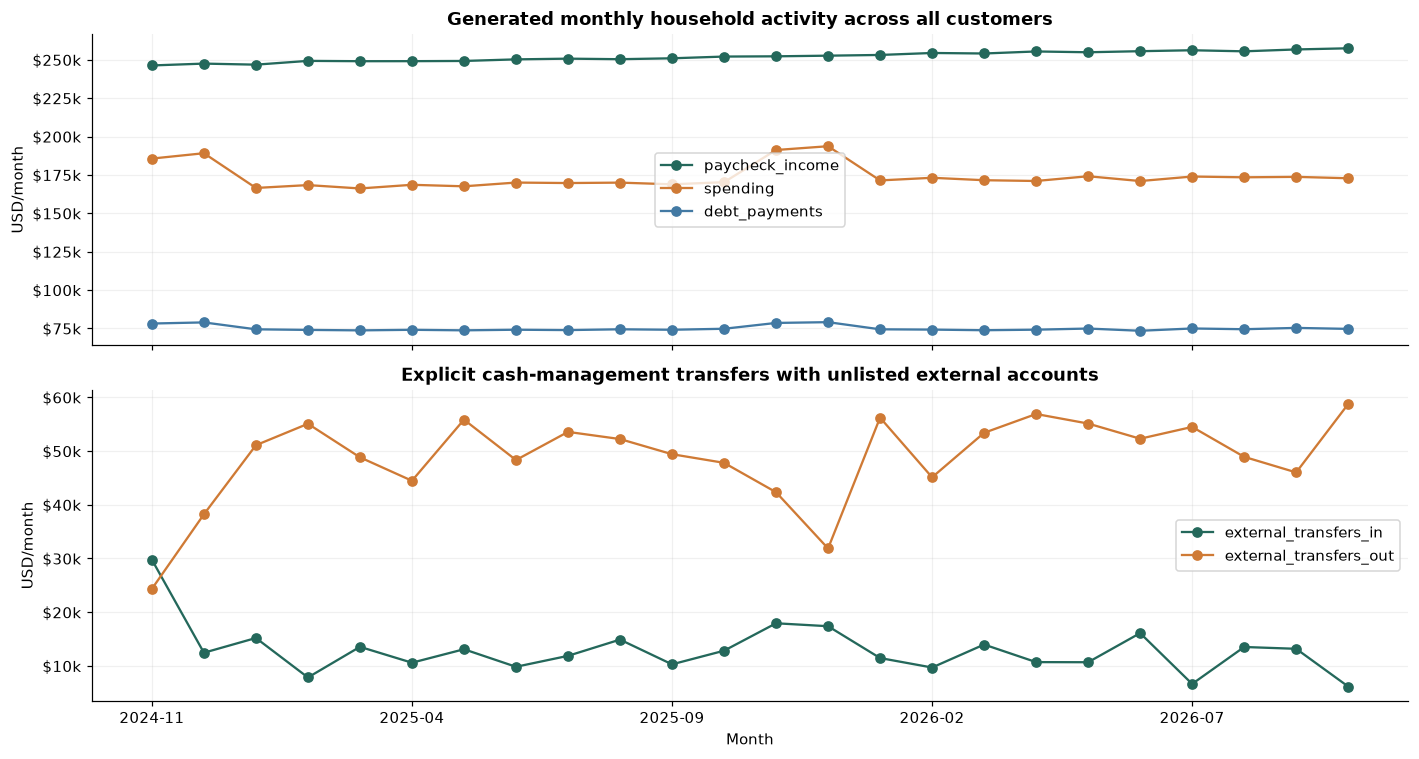

In [24]:
historical = pd.concat([pd.DataFrame(summarize_transaction_history(cid)['months']).assign(customer_id=cid)
                        for cid in profiles.customer_id], ignore_index=True)
portfolio_months = historical.groupby('month').sum(numeric_only=True)
spending_check = transactions.loc[transactions.flow_class.eq('expense')].amount_cents.sum()
assert round(historical.spending.sum() * 100) == spending_check
assert len(historical) == len(profiles) * history_manifest['months']
display(portfolio_months[['paycheck_income','spending','debt_payments','debt_interest','fees','asset_interest',
                        'income_less_spending_and_charges','external_transfers_in','external_transfers_out']])
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
portfolio_months[['paycheck_income','spending','debt_payments']].plot(ax=axes[0], color=[TEAL,ORANGE,BLUE], marker='o')
axes[0].set(title='Generated monthly household activity across all customers', ylabel='USD/month')
portfolio_months[['external_transfers_in','external_transfers_out']].plot(ax=axes[1], color=[TEAL,ORANGE], marker='o')
axes[1].set(title='Explicit cash-management transfers with unlisted external accounts', ylabel='USD/month', xlabel='Month')
for ax in axes:
    ax.yaxis.set_major_formatter(money_axis)
show_plot(fig, '14_monthly_transaction_activity')

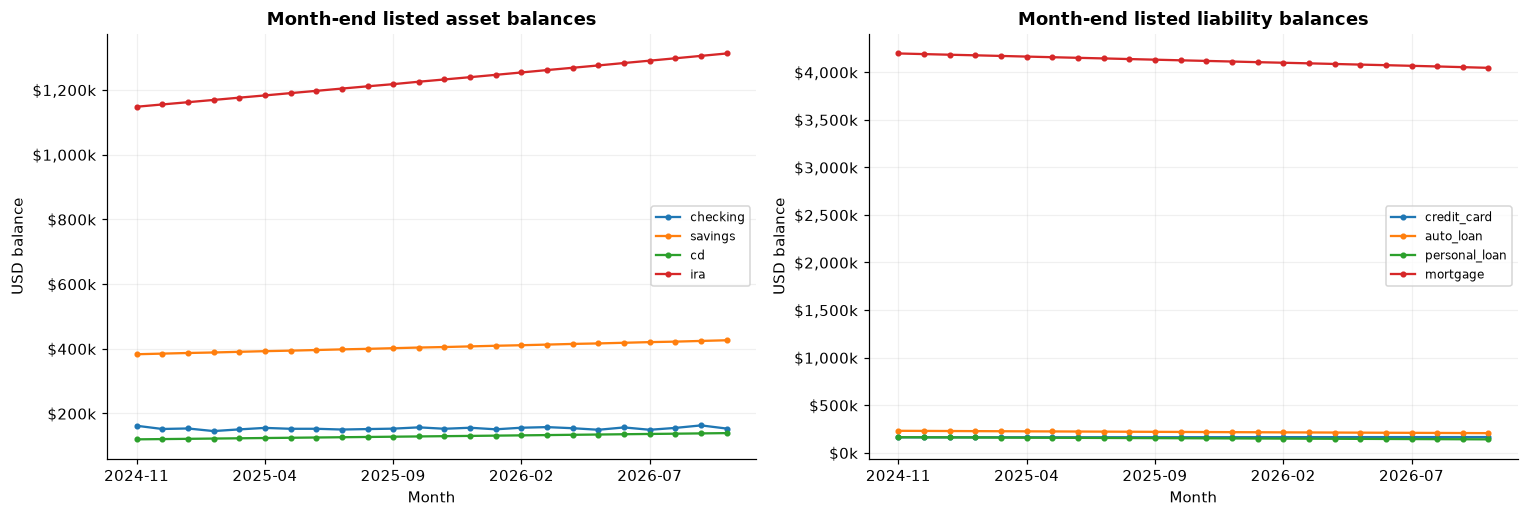

In [25]:
monthly_balances = statements.groupby(['month','account_type']).closing_balance.sum().unstack(fill_value=0).reindex(columns=TYPE_ORDER, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
monthly_balances[ASSETS].plot(ax=axes[0], marker='.', title='Month-end listed asset balances')
monthly_balances[DEBTS].plot(ax=axes[1], marker='.', title='Month-end listed liability balances')
for ax in axes:
    ax.set(xlabel='Month', ylabel='USD balance')
    ax.yaxis.set_major_formatter(money_axis)
    ax.legend(fontsize=8)
show_plot(fig, '15_monthly_account_balances')

last_month = historical.month.max()
last_history = historical.loc[historical.month.eq(last_month)].set_index('customer_id')
assert np.allclose(last_history.closing_assets.reindex(customer.customer_id), customer.total_assets)
assert np.allclose(last_history.closing_debts.reindex(customer.customer_id), customer.total_debts)
assert np.allclose(last_history.closing_liquid_assets.reindex(customer.customer_id), customer.liquid_assets)

### Spending categories, interest, fees, and account activity

Fees are generated servicing/card charges, not evidence of late payments or delinquency. APRs and synthetic yields are fixed model inputs. IRA accrued interest is deliberately a simplified teaching construct; no claim about actual investment returns is supported.

,entries,amount,spending_share_pct
category,,,
housing,720,"1,463,460.80",35.08
groceries,1440,"717,252.25",17.19
other_spending,840,"652,142.38",15.63
utilities,720,"650,425.65",15.59
shopping,720,"229,444.51",5.50
dining,720,"229,434.21",5.50
transport,720,"229,434.21",5.50


transaction_type,fee,interest_accrual
account_type,,
auto_loan,225.00,"32,934.11"
cd,0.00,"10,969.17"
credit_card,"1,350.00","73,598.99"
ira,0.00,"85,806.41"
mortgage,315.00,"536,684.58"
personal_loan,315.00,"33,749.91"
savings,0.00,"20,183.96"


transaction_type,deposit,deposit_rounding,fee,interest_accrual,paycheck,payment,purchase,transfer_out,withdrawal
account_type,,,,,,,,,
checking,333,0,0,0,1440,4248,0,1902,1227
savings,720,2,0,720,720,120,0,0,120
cd,456,0,0,456,0,0,0,0,0
ira,720,4,0,720,0,0,0,0,0
credit_card,0,0,90,720,0,720,2880,0,0
auto_loan,0,0,45,360,0,360,0,0,0
personal_loan,0,0,63,504,0,504,0,0,0
mortgage,0,0,63,504,0,504,0,0,0


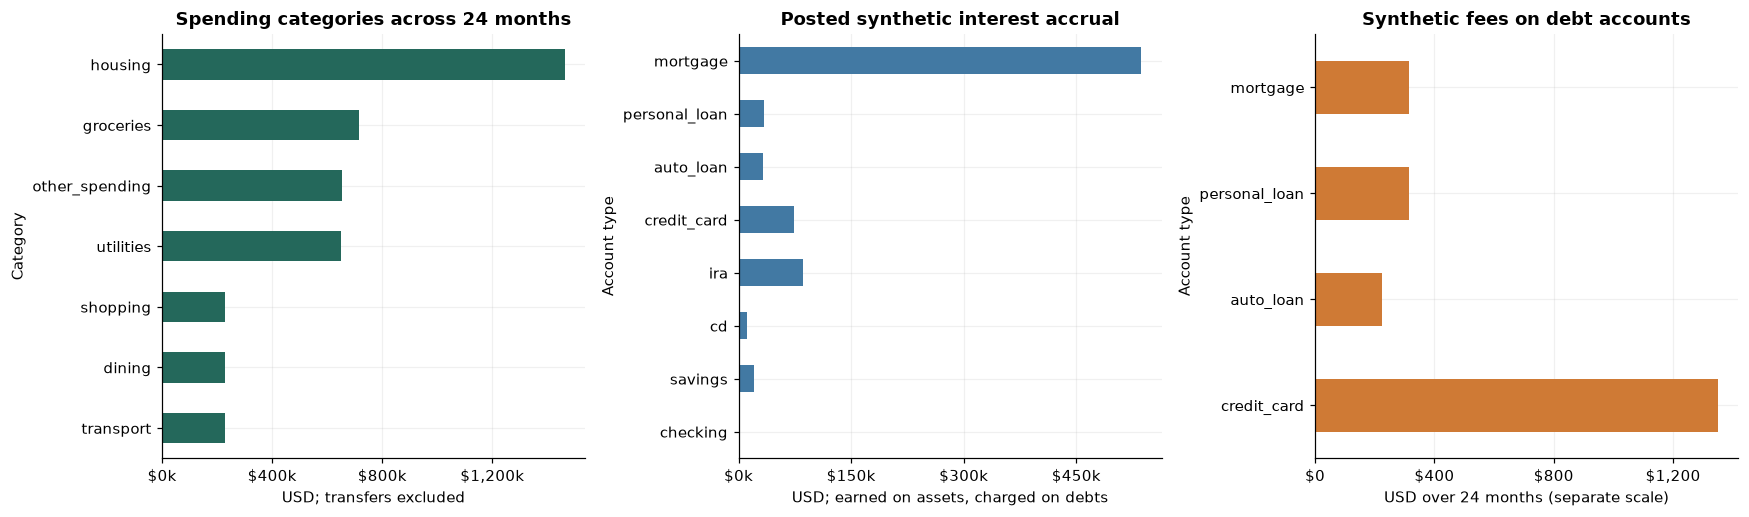

In [26]:
spending_categories = transactions.loc[transactions.flow_class.eq('expense')].groupby('category').agg(
    entries=('transaction_id','size'), amount=('amount','sum')).sort_values('amount', ascending=False)
spending_categories['spending_share_pct'] = 100 * spending_categories.amount / spending_categories.amount.sum()
charge_rows = transactions.loc[transactions.transaction_type.isin(['interest_accrual','fee'])].copy()
charges_by_type = charge_rows.pivot_table(index='account_type', columns='transaction_type', values='amount', aggfunc='sum', fill_value=0)
display(spending_categories)
display(charges_by_type)
display(pd.crosstab(transactions.account_type, transactions.transaction_type).reindex(TYPE_ORDER, fill_value=0))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
spending_categories.amount.sort_values().plot.barh(ax=axes[0], color=TEAL)
axes[0].set(title='Spending categories across 24 months', xlabel='USD; transfers excluded', ylabel='Category')
charges_by_type['interest_accrual'].reindex(TYPE_ORDER, fill_value=0).plot.barh(ax=axes[1], color=BLUE)
axes[1].set(title='Posted synthetic interest accrual', xlabel='USD; earned on assets, charged on debts', ylabel='Account type')
charges_by_type['fee'].reindex(DEBTS, fill_value=0).plot.barh(ax=axes[2], color=ORANGE)
axes[2].set(title='Synthetic fees on debt accounts', xlabel='USD over 24 months (separate scale)', ylabel='Account type')
from matplotlib.ticker import MaxNLocator
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_formatter(money_axis)
axes[2].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x:,.0f}'))
show_plot(fig, '16_categories_interest_fees')

### Generated calendar patterns and within-customer variation

The generator deliberately increases spending in November and December and varies payroll slightly over time. The following plot visualizes those assumptions; it does not discover real-world seasonality. Two observations per calendar month cannot establish a stable seasonal process.

,mean_generated_spending,observations
calendar_month,,
1,"168,945.51",2
2,"170,735.74",2
3,"168,846.54",2
4,"169,787.90",2
5,"170,844.13",2
6,"170,497.28",2
7,"171,810.54",2
8,"171,696.28",2
9,"171,290.30",2


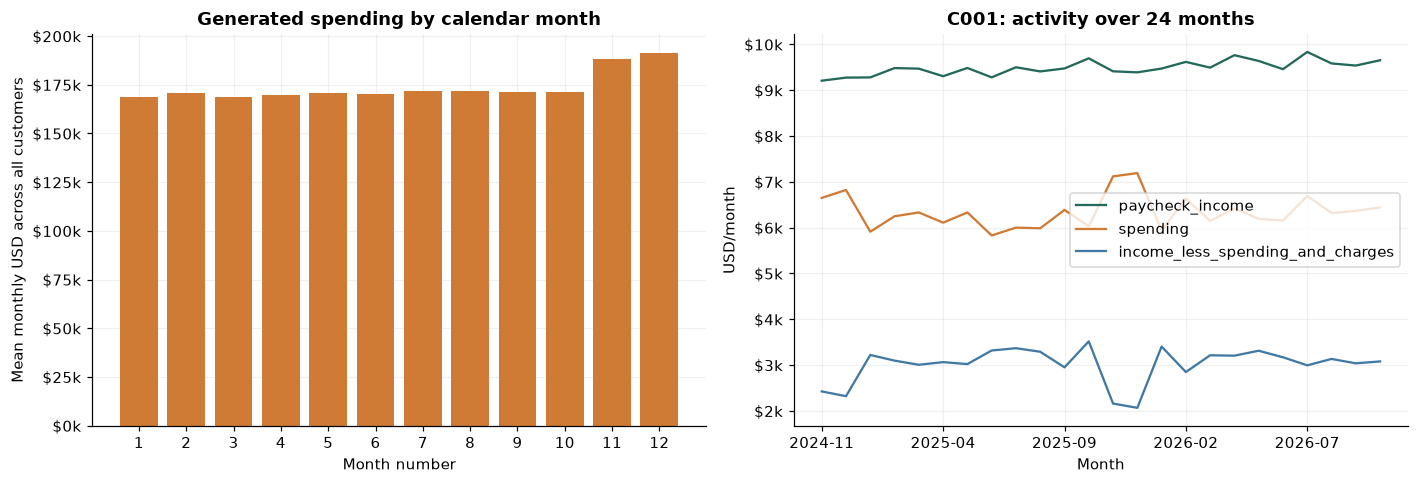

,transaction_id,customer_id,account_id,account_type,posted_date,transaction_type,category,description,amount,balance_change,balance_after,flow_class,transfer_id
0,T0000396,C001,A-C001-IRA,ira,2026-10-31,interest_accrual,asset_interest,Interest accrual,20.34,20.34,"6,994.56",non_cash,
1,T0000348,C001,A-C001-SAVINGS,savings,2026-10-31,interest_accrual,asset_interest,Interest accrual,36.21,36.21,"17,416.60",non_cash,
2,T0000268,C001,A-C001-CHECKING,checking,2026-10-31,withdrawal,external_cash_management,Synthetic withdrawal to an unlisted external a...,"2,916.56","-2,916.56","1,604.00",external_transfer,
3,T0000543,C001,A-C001-CREDIT_CARD,credit_card,2026-10-28,payment,debt_payment,Payment,"1,534.41","-1,534.41","6,571.46",internal_transfer,X-C001-credit_card-23-payment
4,T0000267,C001,A-C001-CHECKING,checking,2026-10-28,payment,debt_payment,Synthetic linked credit card payment,"1,534.41","-1,534.41","4,520.56",internal_transfer,X-C001-credit_card-23-payment
5,T0000542,C001,A-C001-CREDIT_CARD,credit_card,2026-10-26,interest_accrual,debt_interest,Interest accrual,123.11,123.11,"8,105.87",non_cash,
6,T0000541,C001,A-C001-CREDIT_CARD,credit_card,2026-10-25,purchase,shopping,Purchase,354.21,354.21,"7,982.76",expense,
7,T0000266,C001,A-C001-CHECKING,checking,2026-10-25,payment,other_spending,Payment,"1,004.64","-1,004.64","6,054.97",expense,
8,T0000594,C001,A-C001-PERSONAL_LOAN,personal_loan,2026-10-21,payment,debt_payment,Payment,15.21,-15.21,"1,050.28",internal_transfer,X-C001-personal_loan-23-payment
9,T0000265,C001,A-C001-CHECKING,checking,2026-10-21,payment,debt_payment,Synthetic linked personal loan payment,15.21,-15.21,"7,059.61",internal_transfer,X-C001-personal_loan-23-payment


In [27]:
portfolio_months['calendar_month'] = pd.to_datetime(portfolio_months.index).month
seasonal = portfolio_months.groupby('calendar_month').agg(mean_generated_spending=('spending','mean'), observations=('spending','size')).reindex(range(1,13))
display(seasonal)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(seasonal.index, seasonal.mean_generated_spending, color=ORANGE)
axes[0].set(xticks=range(1,13), title='Generated spending by calendar month', xlabel='Month number', ylabel='Mean monthly USD across all customers')
axes[0].yaxis.set_major_formatter(money_axis)
selected_history = historical.loc[historical.customer_id.eq(CUSTOMER_ID)].set_index('month')
selected_history[['paycheck_income','spending','income_less_spending_and_charges']].plot(ax=axes[1], color=[TEAL,ORANGE,BLUE])
axes[1].set(title=f'{CUSTOMER_ID}: activity over 24 months', xlabel='Month', ylabel='USD/month')
axes[1].yaxis.set_major_formatter(money_axis)
show_plot(fig, '17_generated_seasonality_and_customer_history')
display(pd.DataFrame(get_transactions(CUSTOMER_ID, limit=12)['items']))

## 12. Customer drill-down and findings

Change `CUSTOMER_ID` in the setup cell and rerun to compare a household with the full dataset. Percentile rank indicates position within this synthetic sample and does not label a higher value as better. Ties use the average rank. Read each figure with its denominator and source limitations.

In [28]:
if CUSTOMER_ID not in set(customer.customer_id):
    raise ValueError(f'Unknown synthetic customer: {CUSTOMER_ID}')
selected = customer.set_index('customer_id').loc[CUSTOMER_ID]
display(profiles.loc[profiles.customer_id.eq(CUSTOMER_ID)])
display(accounts.loc[accounts.customer_id.eq(CUSTOMER_ID)])
drill = pd.DataFrame({'customer_value': selected[metric_columns],
                     'sample_median': customer[metric_columns].median(),
                     'percentile_rank_pct': customer[metric_columns].rank(pct=True, method='average').loc[
                         customer.customer_id.eq(CUSTOMER_ID)].iloc[0] * 100})
display(drill)
display(vehicle.loc[vehicle.customer_id.eq(CUSTOMER_ID)])

,customer_id,monthly_income,monthly_non_debt_expenses,credit_limit
0,C001,"9,710.63","6,359.87","25,193.32"


,customer_id,account_type,balance,monthly_payment,apr_pct,account_id,opening_balance,history_start,as_of_date,annual_yield_pct
0,C001,checking,"1,604.00",0.00,0.00,A-C001-CHECKING,"1,443.60",2024-11-01,2026-10-31,0.00
1,C001,savings,"17,416.60",0.00,0.00,A-C001-SAVINGS,"15,538.56",2024-11-01,2026-10-31,2.50
2,C001,ira,"6,994.56",0.00,0.00,A-C001-IRA,"6,058.32",2024-11-01,2026-10-31,3.50
3,C001,credit_card,"6,571.46",197.14,22.50,A-C001-CREDIT_CARD,"6,440.03",2024-11-01,2026-10-31,0.00
4,C001,personal_loan,"1,050.28",29.17,11.00,A-C001-PERSONAL_LOAN,"1,234.39",2024-11-01,2026-10-31,0.00


,customer_value,sample_median,percentile_rank_pct
monthly_cash_surplus,"3,124.45","1,272.89",83.33
emergency_fund_months,2.89,2.77,56.67
debt_payment_to_income_pct,2.33,14.15,6.67
credit_card_utilization_pct,26.08,30.70,40.00
savings_rate_pct,32.18,19.22,76.67
net_worth_partial,"18,393.42","-86,509.25",70.00
liquid_assets_to_debt_pct,249.56,12.22,96.67
monthly_debt_payments,226.31,"1,219.43",3.33


,customer_id,new_monthly_payment,projected_monthly_surplus,remaining_liquid_assets,projected_emergency_fund_months,monthly_cash_surplus,liquid_assets,emergency_fund_months,down_payment_exceeds_liquidity,negative_projected_surplus,surplus_change
0,C001,506.91,"2,617.54","14,020.60",1.98,"3,124.45","19,020.60",2.89,False,False,-506.91


In [29]:
negative = int(customer.monthly_cash_surplus.lt(0).sum())
below_reference = int(customer.emergency_fund_months.lt(RESERVE_REFERENCE_MONTHS).sum())
over_limit = int(customer.credit_card_utilization_pct.gt(100).sum())
top_five_share = 100 * debt_rank.head(min(5, n)).total_debts.sum() / total_debt if total_debt else np.nan
vehicle_negative = int(vehicle.negative_projected_surplus.sum())
display(Markdown(f"""### Findings calculated from this run

- Coverage: **{n} households and {len(accounts)} account rows**, across {accounts.account_type.nunique()} observed account types.
- Baseline cash flow: **{negative}/{n} households ({100*negative/n:.1f}%)** have negative modeled monthly surplus. Median surplus is **USD {customer.monthly_cash_surplus.median():,.2f}/month**.
- Reserves: **{below_reference}/{n} households** fall below the editable **{RESERVE_REFERENCE_MONTHS:g}-month** teaching reference. Median modeled runway is **{customer.emergency_fund_months.median():.2f} months**.
- Generator realism check: **{over_limit}/{n} households** have credit-card balances above the generated limit. This is retained for inspection, not interpreted as a verified delinquency or lending outcome.
- Debt concentration: the **{min(5,n)} largest debt balances** represent **{top_five_share:.1f}%** of listed debt.
- Vehicle scenario: **{vehicle_negative}/{n} households** have negative projected monthly surplus; **{int(vehicle.down_payment_exceeds_liquidity.sum())}/{n}** cannot cover the modeled down payment from listed liquid assets.

These statements describe the generated snapshot. The data do not establish real household behavior, a population distribution, or credit eligibility.
"""))

### Findings calculated from this run

- Coverage: **30 households and 196 account rows**, across 8 observed account types.
- Baseline cash flow: **9/30 households (30.0%)** have negative modeled monthly surplus. Median surplus is **USD 1,272.89/month**.
- Reserves: **17/30 households** fall below the editable **3-month** teaching reference. Median modeled runway is **2.77 months**.
- Generator realism check: **1/30 households** have credit-card balances above the generated limit. This is retained for inspection, not interpreted as a verified delinquency or lending outcome.
- Debt concentration: the **5 largest debt balances** represent **34.2%** of listed debt.
- Vehicle scenario: **10/30 households** have negative projected monthly surplus; **0/30** cannot cover the modeled down payment from listed liquid assets.

These statements describe the generated snapshot. The data do not establish real household behavior, a population distribution, or credit eligibility.


### Optional exports and reproducibility checks

Set `EXPORT_RESULTS=True` in setup and rerun to export reusable CSV summaries, scenario grids, the source manifest, and chart PNGs. The source CSVs remain unchanged. Derived percentages stay numeric in exports; currency symbols are display formatting only. File hashes below detect accidental modification during the analysis.

In [30]:
export_tables = {
    'transaction_quality': history_quality, 'transaction_reconciliation': statement_checks,
    'historical_customer_months': historical, 'transaction_spending_categories': spending_categories.reset_index(),
    'transaction_charges_by_type': charges_by_type.reset_index(),
    'source_manifest': source_manifest, 'quality_report': quality_report,
    'reconciliation_report': reconciliation_report, 'overview': overview,
    'customer_metrics': customer, 'account_summary': account_summary.reset_index(),
    'indicator_summary': customer[metric_columns].describe().T.reset_index(),
    'portfolio_ratios': portfolio_ratios, 'illustrative_flags': flag_summary.reset_index(),
    'income_segments': segment_summary.reset_index(), 'outliers': outliers,
    'vehicle_scenarios': vehicle, 'vehicle_sensitivity': sensitivity,
    'income_expense_stress': stress,
}
if EXPORT_RESULTS:
    for name, table in export_tables.items():
        table.to_csv(OUT / f'{name}.csv', index=False)
    print(f'Exported {len(export_tables)} CSV tables and chart PNGs to eda_outputs/.')
else:
    print('Exports disabled. Results are embedded in the notebook only.')

pd.testing.assert_frame_equal(profiles_raw, pd.read_csv(DATA / 'profiles.csv', dtype={'customer_id': 'string'}))
pd.testing.assert_frame_equal(accounts_raw, pd.read_csv(DATA / 'accounts.csv', dtype={'customer_id': 'string', 'account_type': 'string'}))
for row in source_manifest.itertuples():
    assert hashlib.sha256((LAB / row.source).read_bytes()).hexdigest() == row.sha256
assert len(customer) == len(profiles) and customer.customer_id.is_unique
assert not np.isinf(customer.select_dtypes(include='number').to_numpy()).any()
print('Completed: source files unchanged; one analytical row per customer; no infinite metrics. Undefined ratios remain NaN.')

Exports disabled. Results are embedded in the notebook only.
Completed: source files unchanged; one analytical row per customer; no infinite metrics. Undefined ratios remain NaN.


### Workshop exercises

1. Explain why averaging household utilization differs from dividing total credit-card balances by total limits. Find the denominator in each calculation.
2. Change the reserve reference from 3 to 6 months. Describe how the count changes without calling it a change in the underlying data.
3. Find a customer with a large listed mortgage and explain why partial net worth may mislead without property values.
4. Change the vehicle term and APR. Compare monthly payment, projected surplus, and reserve runway. Name omitted ownership costs.
5. Pick an IQR outlier and trace it to the original account rows. Decide whether it reflects a structural generator choice or an actual data-quality problem.
6. Explain why an income/expense scatterplot cannot validate real-world household behavior when expenses were generated as a fraction of income.

### What additional data would enable

| Missing input | Analysis it would support |
| --- | --- |
| Real dated transactions and balances | Validate whether synthetic seasonality and cash-flow patterns represent actual behavior |
| Complete asset inventory and property values | More complete net worth and mortgage collateral context |
| Gross/net income definitions and complete obligations | Better-defined affordability ratios |
| Actual transfers and spending categories | Observed savings behavior and category-level budgets |
| Verified outcomes and a representative sampling design | Separately governed predictive evaluation and population inference |

The notebook deliberately avoids a composite wellness score, credit classification, demographic inference, predictive model, or significance test unsupported by this synthetic sample.